# Real EDA: Iranian Customer Churn (v2: sadar struktur klaster)

Tujuan notebook ini: **dasar untuk `model.ipynb`**. Artinya EDA harus menghasilkan keputusan yang aman dipakai untuk pemodelan: fitur mana yang dipercaya, bagaimana data harus dibagi, dan berapa performa yang realistis.

> **Temuan paling penting (dibahas di FASE 2):** baris-baris dataset ini **bukan pelanggan yang independen**. Urutan baris berulang dengan periode tetap: baris `i`, `i+P`, `i+2P`, ... adalah salinan yang sedikit diubah dari satu "profil dasar". Akibatnya ukuran sampel efektif jauh lebih kecil dari jumlah baris, p-value dan interval kepercayaan tingkat baris terlalu optimistis, dan cross-validation acak membocorkan informasi. Seluruh notebook ini disusun ulang di sekitar fakta itu.

Semua angka pada teks insight **dihitung dari kode** (f-string), bukan diketik tangan.

## Peta metrik: tiga jenis "AUC" yang berbeda

| Jenis | Apa | Model? | Dipakai untuk | Bagian |
|---|---|---|---|---|
| **1. AUC fitur tunggal** | nilai fitur dianggap skor risiko, lalu dihitung `roc_auc_score` | Tidak | mengukur kekuatan peringkat satu fitur (setara korelasi) | FASE 4 |
| **2. AUC diagnostik berbasis model, per-profil** | model gradient boosting dilatih/diuji *out-of-fold*, dengan seluruh baris satu profil selalu berada di fold yang sama | Ya | menguji ablasi fitur dan sensitivitas. **Bukan evaluasi final** | FASE 5-6 |
| **3. AUC cross-validation acak** | seperti jenis 2 tetapi fold diacak per baris | Ya | **hanya untuk memperlihatkan kebocoran**; jangan dipakai sebagai performa | FASE 2 |

Evaluasi final model tetap harus dilakukan di `model.ipynb`. Notebook ini tidak menyisihkan holdout baris-acak karena akan terkontaminasi salinan profil yang sama (lihat FASE 2 dan FASE 7).

## Perubahan dibanding versi sebelumnya
Beberapa klaim di Real_EDA versi pertama **ditarik** karena tidak tahan uji di level profil (Age_Group, ambang tenure 12 bulan, Call_Failure sebagai *suppressor*, dan "AUC 0.98 sebagai red flag leakage" yang kini dijelaskan). Daftar lengkap ada di Lampiran.

# Konteks, Sumber, dan Verifikasi

**Sumber.** Jafari-Marandi, R., Denton, J., Idris, A., Smith, B. K., & Keramati, A. (2020). *Iranian Churn Dataset*. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/563/iranian+churn+dataset (DOI 10.24432/C5JW3Z, CC BY 4.0).

**Yang dikatakan dokumentasi UCI** (dibaca langsung dari halaman, November 2026): data "randomly collected from an Iranian telecom company's database over a period of 12 months", 3.150 baris, satu baris = satu pelanggan. *"All of the attributes except for attribute churn is the aggregated data of the first 9 months. The churn labels are the state of the customers at the end of 12 months. The three months is the designated planning gap."* Halaman itu **tidak menyebut duplikasi, replikasi, atau pra-pemrosesan lain**, dan tidak mencantumkan makalah terkait.

**Hal yang berbeda antara dokumentasi dan data:**
- `Charge Amount` didokumentasikan ordinal 0-9; data berisi 0-**10**.
- Dokumentasi menyebut atribut *Anonymous Customer ID*; **CSV tidak punya kolom ID**.
- `Customer Value` hanya disebut "the calculated value of customer" tanpa rumus (rumusnya ditemukan di FASE 2).

**Pemakaian dalam literatur** (dua makalah dibaca langsung; **keduanya memakai pembagian acak per baris**).
- Faraji Googerdchi dkk. (2024, *PLOS ONE* 19(6): e0303881, https://journals.plos.org/plosone/article?id=10.1371%2Fjournal.pone.0303881): 3.150 pelanggan, 11 atribut (Tabel 5), seleksi NCA membuang `Charge Amount`, `Frequency of SMS`, dan `Tariff Plan` (tiga fitur yang juga kita temukan redundan), pembagian acak 70/10/20 diulang 5×, tidak menyebut deduplikasi. Dua catatan dari Tabel 5 mereka: **`Status` dilabeli "intermediate variable"**, dan `Frequency of use` didefinisikan "number of calls *received*" (UCI: "total number of calls"). Metrik "AUC" mereka dihitung `(1 + TPR − FPR)/2` (Pers. 10), yaitu **akurasi seimbang pada satu ambang, bukan luas di bawah kurva ROC**, sehingga tidak sebanding langsung dengan ROC-AUC.
- Damuri dkk. (2026, *ALMUISY* 5(1), berbahasa Indonesia, https://journal.almuslim.ac.id/index.php/almuisy/en/article/download/183/167): 13 prediktor, pembagian 80/20 berstrata (`random_state` 42; 2.520 latih / 630 uji, jadi **tidak ada baris yang dibuang**), SMOTENC di dalam fold, ROC-AUC uji 0,9912. Mereka memeriksa "kombinasi fitur identik" tetapi tidak membuangnya, dan tidak mengelompokkan per profil.
- Replikasi kedua pipeline pada data ini ada di FASE 2 E.
- Makalah asli Jafari-Marandi dkk. (*Neural Computing and Applications* 32, 2020) **tidak dapat saya akses** (kesalahan sertifikat Springer), jadi isinya tidak diklaim di sini.

**Verifikasi file.** Salinan resmi dari UCI (diambil dengan paket `ucimlrepo`, id = 563) **identik sel demi sel dan urutan barisnya** dengan `Customer Churn.csv` yang dipakai di sini (0 selisih dari 3.150 × 14 sel). Jadi struktur yang ditemukan di FASE 2 adalah sifat dataset aslinya, bukan kerusakan file lokal. Pemeriksaan ini dijalankan di luar notebook; kodenya:
```python
from ucimlrepo import fetch_ucirepo
r = fetch_ucirepo(id=563); uci = pd.concat([r.data.features, r.data.targets], axis=1)
```

**Kamus data** (UCI; hal yang diverifikasi di data ditandai).

| Kolom | Arti |
|---|---|
| `Call_Failure` | jumlah panggilan gagal |
| `Complains` | 0 = tidak ada komplain, 1 = komplain |
| `Subscription_Length` | total bulan berlangganan |
| `Charge_Amount` | ordinal tingkat tagihan (data 0-10) |
| `Seconds_of_Use` / `Frequency_of_use` / `Frequency_of_SMS` / `Distinct_Called_Numbers` | total detik panggilan / jumlah panggilan / jumlah SMS / jumlah nomor berbeda |
| `Age_Group` / `Age` | kelompok usia ordinal 1-5 / usia perwakilan (1:1, diverifikasi di FASE 1) |
| `Tariff_Plan` | 1 = pay-as-you-go, 2 = contractual |
| `Status` | 1 = aktif, 2 = non-aktif |
| `Customer_Value` | skor hasil hitung (formula di FASE 2) |
| `Churn` | 1 = churn pada bulan ke-12 |

**Sikap asosiatif.** Fitur mendahului label (jeda 3 bulan), tetapi urutan waktu *antar-fitur* tidak diketahui. Semua temuan bersifat asosiatif, bukan kausal.

In [1]:
import re, json, itertools, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

import statsmodels.api as sm
from scipy.stats import chi2_contingency, fisher_exact, spearmanr, skew, mannwhitneyu
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, roc_curve
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.linear_model import LinearRegression, LogisticRegression

SEED, TARGET = 180915, 'Churn'
rng = np.random.default_rng(SEED)
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)

BG, PANEL, TEXT, GRID = '#0f1117', '#1a1d27', '#e8eaf0', '#2e3250'
C0, C1, ACC = '#4fc3f7', '#ef9a9a', '#ffd54f'
plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': PANEL, 'axes.edgecolor': GRID, 'axes.labelcolor': TEXT,
    'axes.titlecolor': TEXT, 'xtick.color': TEXT, 'ytick.color': TEXT, 'text.color': TEXT,
    'grid.color': GRID, 'grid.linestyle': '--', 'grid.alpha': 0.4, 'axes.grid': True,
    'legend.facecolor': PANEL, 'legend.edgecolor': GRID, 'figure.dpi': 90,
})

def md(text):
    display(Markdown(text))

def wilson(k, n, z=1.96):
    """CI Wilson 95% untuk proporsi k/n. CATATAN: mengasumsikan baris independen (NAIF di dataset ini)."""
    if n == 0:
        return np.nan, np.nan
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return max(0.0, c - h), min(1.0, c + h)

def rate_table(data, by):
    t = data.groupby(by, observed=True)[TARGET].agg(n='count', churn='sum').reset_index()
    t['rate'] = t.churn / t.n * 100
    ci = [wilson(k, n) for k, n in zip(t.churn, t.n)]
    t['ci_lo'] = [c[0] * 100 for c in ci]; t['ci_hi'] = [c[1] * 100 for c in ci]
    return t

def yerr(t):
    return [np.clip(t.rate - t.ci_lo, 0, None), np.clip(t.ci_hi - t.rate, 0, None)]

# FASE 1: Data Preparation

In [2]:
CANDIDATES = [Path('../dataset/Customer Churn.csv'), Path('dataset/Customer Churn.csv'),
              Path(r'A:/project_iranian_churn/dataset/Customer Churn.csv')]
DATA_PATH = next(p for p in CANDIDATES if p.exists())

raw = pd.read_csv(DATA_PATH)
raw.columns = [re.sub(r'\s+', '_', c.strip()) for c in raw.columns]   # 'Call  Failure' -> 'Call_Failure'
FEATURE_COLS = list(raw.columns)
raw['orig_pos'] = raw.index          # posisi baris di file asli (penting untuk FASE 2)

print('Sumber :', DATA_PATH.resolve())
print('Bentuk :', raw[FEATURE_COLS].shape, '| missing value:', int(raw[FEATURE_COLS].isna().sum().sum()))
raw[FEATURE_COLS].head()

Sumber : A:\project_iranian_churn\dataset\Customer Churn.csv
Bentuk : (3150, 14) | missing value: 0


,Call_Failure,Complains,Subscription_Length,Charge_Amount,Seconds_of_Use,Frequency_of_use,Frequency_of_SMS,Distinct_Called_Numbers,Age_Group,Tariff_Plan,Status,Age,Customer_Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


## A. Duplikat

In [3]:
dup_extra = raw.duplicated(subset=FEATURE_COLS, keep='first')    # salinan ke-2, ke-3, ...
dup_group = raw.duplicated(subset=FEATURE_COLS, keep=False)      # semua baris dalam grup duplikat
n_raw, n_extra, n_in_groups = len(raw), int(dup_extra.sum()), int(dup_group.sum())
groups = raw[dup_group].groupby(FEATURE_COLS).size().rename('k').reset_index()
n_groups, n_triplets = len(groups), int((groups.k == 3).sum())
n_nonzero_groups = int(((groups.Seconds_of_Use > 0) & (groups.Customer_Value > 0)).sum())

summary = pd.DataFrame({
    'n baris': [n_raw, n_extra, n_in_groups, n_raw - n_in_groups],
    'churn rate (%)': [raw[TARGET].mean() * 100, raw.loc[dup_extra, TARGET].mean() * 100,
                       raw.loc[dup_group, TARGET].mean() * 100, raw.loc[~dup_group, TARGET].mean() * 100],
}, index=['Semua data', 'Salinan ekstra (yang dihapus)', 'Semua baris dalam grup duplikat', 'Baris tanpa duplikat']).round(2)
display(summary)
print('Ukuran grup duplikat (ukuran: jumlah grup):', groups.k.value_counts().sort_index().to_dict())

md(f"""
**Duplikat persis.** {n_extra} salinan ekstra ({n_extra / n_raw * 100:.2f}% data); angka churn 17.4% milik **{n_in_groups} baris** dalam grup duplikat (termasuk aslinya), sedangkan 300 salinan sendiri {raw.loc[dup_extra, TARGET].mean() * 100:.1f}%. Ada {n_groups} grup; **{n_triplets} muncul tepat 3×**, dan {n_nonzero_groups} grup punya Seconds_of_Use dan Customer_Value desimal > 0 yang identik di semua 14 kolom. Kebetulan seperti itu hampir mustahil pada pelanggan independen. **Keputusan: hapus** salinan ekstra. Alasan sebenarnya ditemukan di FASE 2 (struktur replikasi), yang jauh lebih luas daripada duplikat persis ini.
""")

,n baris,churn rate (%)
Semua data,3150,15.71
Salinan ekstra (yang dihapus),300,16.33
Semua baris dalam grup duplikat,465,17.42
Baris tanpa duplikat,2685,15.42


Ukuran grup duplikat (ukuran: jumlah grup): {2: 44, 3: 113, 4: 4, 5: 2, 6: 2}



**Duplikat persis.** 300 salinan ekstra (9.52% data); angka churn 17.4% milik **465 baris** dalam grup duplikat (termasuk aslinya), sedangkan 300 salinan sendiri 16.3%. Ada 165 grup; **113 muncul tepat 3×**, dan 142 grup punya Seconds_of_Use dan Customer_Value desimal > 0 yang identik di semua 14 kolom. Kebetulan seperti itu hampir mustahil pada pelanggan independen. **Keputusan: hapus** salinan ekstra. Alasan sebenarnya ditemukan di FASE 2 (struktur replikasi), yang jauh lebih luas daripada duplikat persis ini.


In [4]:
df = raw[~dup_extra].reset_index(drop=True)
assert df.duplicated(subset=FEATURE_COLS).sum() == 0

assert (df.groupby('Age_Group')['Age'].nunique() == 1).all(), 'Age_Group tidak 1:1 dengan Age'
AGE_VALUE = df.groupby('Age_Group')['Age'].first().to_dict()
df = df.drop(columns='Age')

NUM = ['Call_Failure', 'Subscription_Length', 'Seconds_of_Use', 'Frequency_of_use',
       'Frequency_of_SMS', 'Distinct_Called_Numbers', 'Customer_Value']
CAT = ['Complains', 'Status', 'Tariff_Plan', 'Age_Group', 'Charge_Amount']
FEATURES = NUM + CAT
N, N_CHURN = len(df), int(df[TARGET].sum()); BASE = N_CHURN / N * 100
md(f"Data setelah dedup: **{N:,} baris** ({N_CHURN} churn, {BASE:.2f}%). `Age` dibuang karena 1:1 dengan `Age_Group` ({AGE_VALUE}).")

Data setelah dedup: **2,850 baris** (446 churn, 15.65%). `Age` dibuang karena 1:1 dengan `Age_Group` ({1: 15, 2: 25, 3: 30, 4: 45, 5: 55}).

# FASE 2: Forensik Data dan Struktur Klaster

Sebelum menganalisis hubungan antar-variabel, kita periksa apakah data memenuhi asumsi paling dasar: **baris yang independen** dan nilai yang masuk akal. Bagian ini menjawabnya.

## A. Validitas logis

In [5]:
S_, F_, SMS_, D_ = 'Seconds_of_Use', 'Frequency_of_use', 'Frequency_of_SMS', 'Distinct_Called_Numbers'
rules = {
    'Seconds > 0 tetapi Frequency_of_use = 0': (df[S_] > 0) & (df[F_] == 0),
    'Frequency_of_use > 0 tetapi Seconds = 0': (df[F_] > 0) & (df[S_] == 0),
    'Distinct_Called_Numbers > Frequency_of_use': df[D_] > df[F_],
    'Call_Failure > Frequency_of_use': df.Call_Failure > df[F_],
    'Customer_Value = 0 tetapi ada pemakaian': (df.Customer_Value == 0) & ((df[S_] > 0) | (df[SMS_] > 0)),
    'Seluruh pemakaian = 0 (detik, panggilan, SMS, nomor)': (df[[S_, F_, SMS_, D_]] == 0).all(axis=1),
}
rule_df = pd.DataFrame([{'aturan': k, 'n': int(m.sum()), '% data': m.mean() * 100,
                         'churn %': df.loc[m, TARGET].mean() * 100 if m.any() else np.nan} for k, m in rules.items()]).set_index('aturan')
display(rule_df.round(1))

viol = rules['Distinct_Called_Numbers > Frequency_of_use']; zero_all = rules['Seluruh pemakaian = 0 (detik, panggilan, SMS, nomor)']
md(f"""
- Konsistensi dasar baik: tidak ada baris dengan detik > 0 tetapi panggilan = 0 (atau sebaliknya), dan Customer_Value = 0 hanya muncul bila tidak ada pemakaian.
- {int(viol.sum())} baris ({viol.mean() * 100:.1f}%) punya `Distinct_Called_Numbers` > `Frequency_of_use`. Ini **hanya** pelanggaran logis bila `Frequency_of_use` = total panggilan (definisi UCI). Makalah PLOS mendefinisikannya "number of calls received" (panggilan *masuk*), sedangkan `Distinct_Called_Numbers` adalah nomor yang *dihubungi* (keluar); bila itu yang benar, kedua kolom tidak punya batas logis satu sama lain. **Tidak ada kesimpulan di sini**; definisi kolom perlu diklarifikasi.
- {int(zero_all.sum())} baris berpemakaian nol total; hanya {df.loc[zero_all, TARGET].mean() * 100:.0f}% di antaranya churn. Pemakaian nol bukan sinonim churn.
""")

,n,% data,churn %
aturan,,,
Seconds > 0 tetapi Frequency_of_use = 0,0,0.0,NaN
Frequency_of_use > 0 tetapi Seconds = 0,0,0.0,NaN
Distinct_Called_Numbers > Frequency_of_use,111,3.9,21.6
Call_Failure > Frequency_of_use,3,0.1,100.0
Customer_Value = 0 tetapi ada pemakaian,0,0.0,NaN
"Seluruh pemakaian = 0 (detik, panggilan, SMS, nomor)",85,3.0,51.8



- Konsistensi dasar baik: tidak ada baris dengan detik > 0 tetapi panggilan = 0 (atau sebaliknya), dan Customer_Value = 0 hanya muncul bila tidak ada pemakaian.
- 111 baris (3.9%) punya `Distinct_Called_Numbers` > `Frequency_of_use`. Ini **hanya** pelanggaran logis bila `Frequency_of_use` = total panggilan (definisi UCI). Makalah PLOS mendefinisikannya "number of calls received" (panggilan *masuk*), sedangkan `Distinct_Called_Numbers` adalah nomor yang *dihubungi* (keluar); bila itu yang benar, kedua kolom tidak punya batas logis satu sama lain. **Tidak ada kesimpulan di sini**; definisi kolom perlu diklarifikasi.
- 85 baris berpemakaian nol total; hanya 52% di antaranya churn. Pemakaian nol bukan sinonim churn.


## B. Pola digit dan Customer_Value

In [6]:
last_digit = (df[S_] % 10).value_counts().reindex(range(10), fill_value=0)
absent_digits = last_digit[last_digit == 0].index.tolist()
cv_x5 = (((df.Customer_Value * 1000).round().astype(int)) % 5 == 0).mean()
display(last_digit.rename('jumlah baris').to_frame().T.rename(index={'jumlah baris': 'digit terakhir Seconds_of_Use'}))

# Customer_Value: regresi linear per Age_Group
rows = []
for ag in sorted(df.Age_Group.unique()):
    sub = df[df.Age_Group == ag]; lr = LinearRegression().fit(sub[[S_, F_, SMS_]], sub.Customer_Value)
    rows.append({'Age_Group': ag, 'n': len(sub), 'R2': lr.score(sub[[S_, F_, SMS_]], sub.Customer_Value),
                 'koef Seconds': lr.coef_[0], 'koef Frequency_of_use': lr.coef_[1], 'koef SMS': lr.coef_[2], 'intersep': lr.intercept_})
cvf = pd.DataFrame(rows).set_index('Age_Group')
cvf['pengali vs Age_Group 3'] = cvf['koef SMS'] / cvf.loc[3, 'koef SMS']
display(cvf.round(5))

MULT = cvf['pengali vs Age_Group 3'].round(3).to_dict()
pred = df.Age_Group.map(MULT) * (0.04 * df[S_] + 0.04 * df[F_] + 4.0 * df[SMS_])
cv_err = (df.Customer_Value - pred).abs()
# R² Customer_Value ~ komponen tanpa pengali usia (membandingkan dengan versi pertama)
lr_nomult = LinearRegression().fit(df[[S_, F_, SMS_]], df.Customer_Value)

md(f"""
**Digit terakhir `Seconds_of_Use`.** Digit {absent_digits} **tidak pernah muncul** dalam {N:,} baris (distribusi: {last_digit.to_dict()}). Durasi panggilan nyata yang dijumlahkan dalam detik akan memiliki digit terakhir yang kira-kira seragam. Pola ini **tidak alami**.

**`Customer_Value` adalah rumus pasti**, bukan "nilai hasil hitung" yang misterius:

`Customer_Value = m(Age_Group) × (0.04 × Seconds_of_Use + 0.04 × Frequency_of_use + 4 × Frequency_of_SMS)`

dengan pengali m = {MULT} untuk Age_Group 1-5. R² regresi per Age_Group = {cvf.R2.min():.5f}-{cvf.R2.max():.5f}; galat absolut rata-rata rumus {cv_err.mean():.5f}, maksimum {cv_err.max():.5f}. Tanpa pengali usia, R² hanya {lr_nomult.score(df[[S_, F_, SMS_]], df.Customer_Value):.3f} (inilah R² 0.957 di versi sebelumnya yang "tidak sempurna"). Konsekuensi: `Customer_Value` **tidak membawa informasi independen sama sekali** (fungsi deterministik dari tiga fitur pemakaian dan `Age_Group`); seluruh analisis yang bertumpu padanya hanya mengulang fitur-fitur itu. Pengali menurun menurut usia (1.375 → 0.375): nilai pelanggan yang lebih tua lebih kecil untuk pemakaian yang sama; ini aturan perhitungan skor, bukan perilaku pelanggan. Semua kelipatan 0.005 pada `Customer_Value`: {cv_x5 * 100:.0f}% baris.
""")

Seconds_of_Use,0,1,2,3,4,5,6,7,8,9
digit terakhir Seconds_of_Use,957,0,35,566,0,777,0,50,465,0


,n,R2,koef Seconds,koef Frequency_of_use,koef SMS,intersep,pengali vs Age_Group 3
Age_Group,,,,,,,
1,112,1.0,0.055,0.055,5.5,-0.0,1.375
2,921,1.0,0.045,0.045,4.5,-0.0,1.125
3,1296,1.0,0.040,0.040,4.0,-0.0,1.000
4,367,1.0,0.025,0.025,2.5,-0.0,0.625
5,154,1.0,0.015,0.015,1.5,-0.0,0.375



**Digit terakhir `Seconds_of_Use`.** Digit [1, 4, 6, 9] **tidak pernah muncul** dalam 2,850 baris (distribusi: {0: 957, 1: 0, 2: 35, 3: 566, 4: 0, 5: 777, 6: 0, 7: 50, 8: 465, 9: 0}). Durasi panggilan nyata yang dijumlahkan dalam detik akan memiliki digit terakhir yang kira-kira seragam. Pola ini **tidak alami**.

**`Customer_Value` adalah rumus pasti**, bukan "nilai hasil hitung" yang misterius:

`Customer_Value = m(Age_Group) × (0.04 × Seconds_of_Use + 0.04 × Frequency_of_use + 4 × Frequency_of_SMS)`

dengan pengali m = {1: 1.375, 2: 1.125, 3: 1.0, 4: 0.625, 5: 0.375} untuk Age_Group 1-5. R² regresi per Age_Group = 1.00000-1.00000; galat absolut rata-rata rumus 0.00000, maksimum 0.00000. Tanpa pengali usia, R² hanya 0.957 (inilah R² 0.957 di versi sebelumnya yang "tidak sempurna"). Konsekuensi: `Customer_Value` **tidak membawa informasi independen sama sekali** (fungsi deterministik dari tiga fitur pemakaian dan `Age_Group`); seluruh analisis yang bertumpu padanya hanya mengulang fitur-fitur itu. Pengali menurun menurut usia (1.375 → 0.375): nilai pelanggan yang lebih tua lebih kecil untuk pemakaian yang sama; ini aturan perhitungan skor, bukan perilaku pelanggan. Semua kelipatan 0.005 pada `Customer_Value`: 100% baris.


## C. Urutan baris: struktur berulang

Pada data pelanggan yang diambil acak, nilai baris `i` dan baris `i+k` seharusnya hampir tidak berkorelasi untuk sembarang `k`. Kita cek autokorelasi menurut jarak baris (pada data mentah, sebelum dedup).

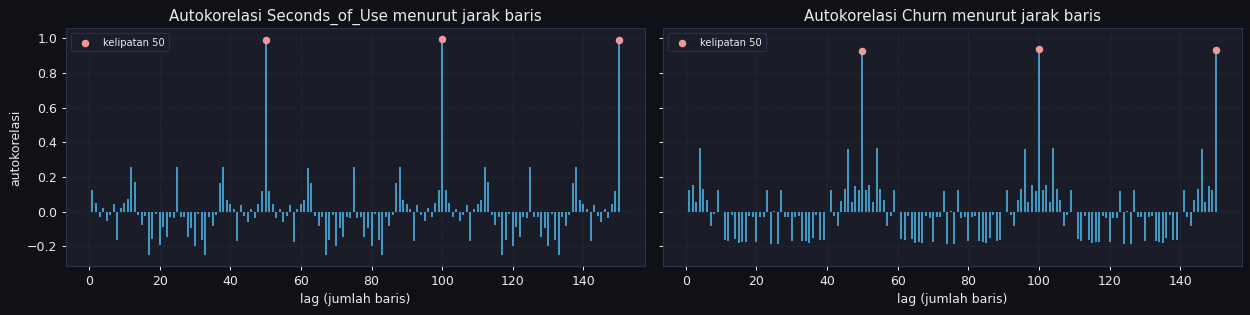

,autokorelasi Seconds,autokorelasi Churn,Churn sama (%),Status sama (%),Tariff_Plan sama (%)
lag,,,,,
1,0.128,0.123,76.786,69.387,85.456
49,0.119,0.123,76.782,68.462,85.553
50,0.990,0.926,98.032,97.355,97.484
51,0.119,0.124,76.831,68.441,85.479
100,0.995,0.942,98.459,97.803,97.443
150,0.991,0.932,98.200,97.700,97.400



Autokorelasi `Seconds_of_Use` melompat dari ≤ 0.26 (lag 1-49) menjadi **0.99 tepat pada lag 50** dan tetap ~0.99 pada kelipatannya, sementara di lag 49 dan 51 kembali ke ~0.12. Label `Churn` pada baris `i` dan `i+50` sama pada **98.0%** pasangan (dua baris acak sama pada ~74%).

Ini berarti data tersusun dari **50 "profil dasar"**, masing-masing muncul ≈ 63 kali (baris `i`, `i+50`, `i+100`, ...) dengan variasi (jitter) pada sebagian kolom. Mekanisme pasti pembuatannya **tidak diketahui**; polanya konsisten dengan replikasi/augmentasi sintetis.


In [7]:
LAGS = np.arange(1, 151)
acf_s = np.array([raw[S_].autocorr(l) for l in LAGS])
acf_c = np.array([raw[TARGET].autocorr(l) for l in LAGS])
PERIOD = int(next(l for l, a in zip(LAGS, acf_s) if a > 0.9))     # lag terkecil dengan autokorelasi > 0.9
N_SEEDS = PERIOD

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), sharey=True)
for ax, a, nm in zip(axes, [acf_s, acf_c], ['Seconds_of_Use', 'Churn']):
    ax.vlines(LAGS, 0, a, color=C0, lw=1.2)
    ax.scatter(LAGS[LAGS % PERIOD == 0], a[LAGS % PERIOD == 0], color=C1, zorder=3, s=25, label=f'kelipatan {PERIOD}')
    ax.set_title(f'Autokorelasi {nm} menurut jarak baris'); ax.set_xlabel('lag (jumlah baris)'); ax.legend(fontsize=8)
axes[0].set_ylabel('autokorelasi')
plt.tight_layout(); plt.show()

base_agree = (raw[TARGET].mean() ** 2 + (1 - raw[TARGET].mean()) ** 2)
rows = []
for lag in [1, PERIOD - 1, PERIOD, PERIOD + 1, 2 * PERIOD, 3 * PERIOD]:
    x, y_ = raw.iloc[:-lag], raw.iloc[lag:]
    rows.append({'lag': lag, 'autokorelasi Seconds': raw[S_].autocorr(lag), 'autokorelasi Churn': raw[TARGET].autocorr(lag),
                 'Churn sama (%)': (x[TARGET].values == y_[TARGET].values).mean() * 100,
                 'Status sama (%)': (x.Status.values == y_.Status.values).mean() * 100,
                 'Tariff_Plan sama (%)': (x.Tariff_Plan.values == y_.Tariff_Plan.values).mean() * 100})
lag_df = pd.DataFrame(rows).set_index('lag'); display(lag_df.round(3))

md(f"""
Autokorelasi `Seconds_of_Use` melompat dari ≤ {np.abs(acf_s[:PERIOD - 1]).max():.2f} (lag 1-{PERIOD - 1}) menjadi **{acf_s[PERIOD - 1]:.2f} tepat pada lag {PERIOD}** dan tetap ~0.99 pada kelipatannya, sementara di lag {PERIOD - 1} dan {PERIOD + 1} kembali ke ~{raw[S_].autocorr(PERIOD - 1):.2f}. Label `Churn` pada baris `i` dan `i+{PERIOD}` sama pada **{(raw[TARGET].values[:-PERIOD] == raw[TARGET].values[PERIOD:]).mean() * 100:.1f}%** pasangan (dua baris acak sama pada ~{base_agree * 100:.0f}%).

Ini berarti data tersusun dari **{PERIOD} "profil dasar"**, masing-masing muncul ≈ {n_raw / PERIOD:.0f} kali (baris `i`, `i+{PERIOD}`, `i+{2 * PERIOD}`, ...) dengan variasi (jitter) pada sebagian kolom. Mekanisme pasti pembuatannya **tidak diketahui**; polanya konsisten dengan replikasi/augmentasi sintetis.
""")

## D. Profil dasar ("seed"), klaster, dan ukuran sampel efektif

In [8]:
raw['seed'] = raw.orig_pos % N_SEEDS
df['seed'] = df.orig_pos % N_SEEDS

seed_tab = df.groupby('seed').agg(
    n=(TARGET, 'size'), churn_rate=(TARGET, 'mean'),
    Status=('Status', lambda x: x.mode()[0]), Plan=('Tariff_Plan', lambda x: x.mode()[0]), Age_Group=('Age_Group', lambda x: x.mode()[0]),
    komplain=('Complains', 'mean'), Seconds=(S_, 'median'), Frequency=(F_, 'median'), SMS=(SMS_, 'median'),
    Distinct=(D_, 'median'), Tenure=('Subscription_Length', 'median'), Call_Failure=('Call_Failure', 'median'))
seed_tab['seed_churn'] = (seed_tab.churn_rate >= 0.5).astype(int)
df['seed_churn'] = df.seed.map(seed_tab.seed_churn)
N_CHURN_SEEDS = int(seed_tab.seed_churn.sum())

def icc_anova(y, g):
    d = pd.DataFrame({'y': np.asarray(y, float), 'g': np.asarray(g)}); k = d.g.nunique(); n = len(d); m = d.groupby('g').size()
    gm = d.groupby('g').y.mean(); grand = d.y.mean()
    ssb = (m * (gm - grand) ** 2).sum(); ssw = ((d.y - d.g.map(gm)) ** 2).sum()
    msb, msw = ssb / (k - 1), ssw / (n - k); n0 = (n - (m ** 2).sum() / n) / (k - 1)
    return (msb - msw) / (msb + (n0 - 1) * msw), n0

icc_rows = {c: icc_anova(df[c], df.seed)[0] for c in [TARGET] + NUM + CAT}
icc_tab = pd.Series(icc_rows, name='ICC (proporsi variasi antar-profil)').sort_values(ascending=False)
ICC_Y, N0 = icc_anova(df[TARGET], df.seed); DEFF = 1 + (N0 - 1) * ICC_Y; N_EFF = N / DEFF
display(icc_tab.round(3).to_frame().T)

hist_purity = np.histogram(seed_tab.churn_rate, bins=[0, .05, .1, .9, .95, 1.01])[0]
md(f"""
- Setelah dedup ada **{df.seed.nunique()} profil**, masing-masing {seed_tab.n.min()}-{seed_tab.n.max()} baris.
- **Kemurnian label**: {int(hist_purity[0] + hist_purity[1])} profil punya churn < 10%, {int(hist_purity[3] + hist_purity[4])} profil churn > 90%, hanya {int(hist_purity[2])} yang campuran. Hanya **{N_CHURN_SEEDS} profil bermayoritas churn** (dari {N_SEEDS}).
- **ICC label = {ICC_Y:.2f}** (rata-rata ukuran klaster {N0:.0f}): hampir seluruh variasi `Churn` terjadi *antar-profil*, bukan antar-baris. **Design effect = {DEFF:.0f}**, sehingga **ukuran sampel efektif ≈ {N_EFF:.0f}** (bukan {N:,}), dengan {N_CHURN_SEEDS} profil positif.
- ICC fitur: pemakaian ≈ {icc_tab[S_]:.2f}, Status {icc_tab['Status']:.2f}, Subscription_Length {icc_tab['Subscription_Length']:.2f}, Age_Group {icc_tab['Age_Group']:.2f}, Call_Failure {icc_tab['Call_Failure']:.2f}, **Complains hanya {icc_tab['Complains']:.2f}** (Complains berubah acak dalam profil). Fitur dengan ICC tinggi berfungsi sebagai **sidik jari profil**: model dapat "mengenali" profil dari nilainya.
""")
display(seed_tab[seed_tab.churn_rate > 0.02].sort_values('churn_rate', ascending=False).round(2))

,Seconds_of_Use,Frequency_of_SMS,Customer_Value,Frequency_of_use,Status,Churn,Distinct_Called_Numbers,Subscription_Length,Age_Group,Tariff_Plan,Charge_Amount,Call_Failure,Complains
ICC (proporsi variasi antar-profil),0.99,0.985,0.978,0.978,0.925,0.923,0.888,0.84,0.818,0.798,0.681,0.62,0.342



- Setelah dedup ada **50 profil**, masing-masing 45-61 baris.
- **Kemurnian label**: 42 profil punya churn < 10%, 7 profil churn > 90%, hanya 1 yang campuran. Hanya **8 profil bermayoritas churn** (dari 50).
- **ICC label = 0.92** (rata-rata ukuran klaster 57): hampir seluruh variasi `Churn` terjadi *antar-profil*, bukan antar-baris. **Design effect = 53**, sehingga **ukuran sampel efektif ≈ 54** (bukan 2,850), dengan 8 profil positif.
- ICC fitur: pemakaian ≈ 0.99, Status 0.93, Subscription_Length 0.84, Age_Group 0.82, Call_Failure 0.62, **Complains hanya 0.34** (Complains berubah acak dalam profil). Fitur dengan ICC tinggi berfungsi sebagai **sidik jari profil**: model dapat "mengenali" profil dari nilainya.


,n,churn_rate,Status,Plan,Age_Group,komplain,Seconds,Frequency,SMS,Distinct,Tenure,Call_Failure,seed_churn
seed,,,,,,,,,,,,,
18,45,1.00,2,1,2,0.13,80.0,2.0,7.0,2.0,38.0,0.0,1
26,59,1.00,2,1,3,0.63,2990.0,41.0,9.0,16.0,35.0,9.0,1
22,60,1.00,2,1,2,0.58,955.0,47.0,16.0,17.0,33.0,23.0,1
28,52,1.00,2,1,3,0.19,230.5,5.5,7.0,2.0,36.0,1.0,1
27,60,1.00,2,1,3,0.53,2268.0,44.0,34.0,31.0,36.0,9.0,1
31,57,1.00,2,1,4,0.23,628.0,7.0,10.0,4.0,36.0,0.0,1
49,61,1.00,1,1,3,0.52,1487.0,19.0,3.0,7.0,9.0,3.0,1
24,59,0.61,1,1,2,0.20,5818.0,98.0,26.0,24.0,36.0,13.0,1
38,59,0.08,1,2,2,0.10,1315.0,36.0,193.0,11.0,27.0,4.0,0


In [9]:
# Hubungan antara duplikat persis dan profil
extra_per_seed = raw.loc[dup_extra, 'seed'].value_counts()
span = raw[dup_group].groupby(FEATURE_COLS).seed.nunique()
pos_dec = np.histogram(raw.loc[dup_extra, 'orig_pos'], bins=np.linspace(0, n_raw, 11))[0]
md(f"""
**Duplikat persis ternyata muncul di dalam profil yang sama**: {int((span == 1).sum())} dari {len(span)} grup duplikat hanya memuat satu profil. {int(extra_per_seed.head(5).sum())} dari {n_extra} salinan ekstra berasal dari 5 profil (`{extra_per_seed.head(5).to_dict()}`), (profil berpemakaian rendah, tempat jitter lebih sering menghasilkan baris identik). Distribusi posisi salinan menurut desil baris: {pos_dec.tolist()}. Jadi duplikat persis hanyalah kasus ekstrem dari replikasi yang jauh lebih luas.
""")

# Komplain vs label di dalam profil
cx = df.groupby(['seed_churn', 'Complains'])[TARGET].agg(['count', 'sum', 'mean']).rename(columns={'count': 'n', 'sum': 'churn', 'mean': 'rate'})
cx['rate'] = (cx['rate'] * 100).round(1)
display(cx)
c_ch1 = cx.loc[(1, 1)]; c_ch0 = cx.loc[(1, 0)]; c_nc1 = cx.loc[(0, 1)]; c_nc0 = cx.loc[(0, 0)]
md(f"""
**`Complains` nyaris mekanis terhadap label.**
- Dalam profil **churn**: baris dengan Complains = 1 churn **{int(c_ch1['churn'])} dari {int(c_ch1['n'])}** ({c_ch1['rate']:.0f}%); semua baris `Churn = 0` di profil churn ({int(c_ch0['n'] - c_ch0['churn'])} baris) berstatus Complains = 0.
- Dalam profil **non-churn**: Complains = 0 hanya churn {c_nc0['rate']:.2f}% ({int(c_nc0['churn'])} dari {int(c_nc0['n']):,}), tetapi Complains = 1 churn **{c_nc1['rate']:.1f}%** ({int(c_nc1['churn'])} dari {int(c_nc1['n'])}).
- Artinya komplain bertindak seperti "pengganti label" yang hampir deterministik: di profil mana pun, pengeluh sangat mungkin berlabel churn. Entah komplain memang memicu churn, atau label/komplain dibangkitkan bersama. **Data ini tidak bisa membedakannya**, dan untuk pemodelan `Complains` harus diperlakukan sebagai fitur yang berisiko mendekati kebocoran label.
""")


**Duplikat persis ternyata muncul di dalam profil yang sama**: 153 dari 165 grup duplikat hanya memuat satu profil. 62 dari 300 salinan ekstra berasal dari 5 profil (`{18: 18, 1: 15, 28: 11, 17: 9, 32: 9}`), (profil berpemakaian rendah, tempat jitter lebih sering menghasilkan baris identik). Distribusi posisi salinan menurut desil baris: [0, 2, 3, 89, 8, 10, 96, 0, 1, 91]. Jadi duplikat persis hanyalah kasus ekstrem dari replikasi yang jauh lebih luas.


n  churn   rate
seed_churn Complains                    
0          0          2344      3    0.1
           1            53     13   24.5
1          0           276    253   91.7
           1           177    177  100.0


**`Complains` nyaris mekanis terhadap label.**
- Dalam profil **churn**: baris dengan Complains = 1 churn **177 dari 177** (100%); semua baris `Churn = 0` di profil churn (23 baris) berstatus Complains = 0.
- Dalam profil **non-churn**: Complains = 0 hanya churn 0.10% (3 dari 2,344), tetapi Complains = 1 churn **24.5%** (13 dari 53).
- Artinya komplain bertindak seperti "pengganti label" yang hampir deterministik: di profil mana pun, pengeluh sangat mungkin berlabel churn. Entah komplain memang memicu churn, atau label/komplain dibangkitkan bersama. **Data ini tidak bisa membedakannya**, dan untuk pemodelan `Complains` harus diperlakukan sebagai fitur yang berisiko mendekati kebocoran label.


## E. Dampak pada evaluasi: cross-validation acak vs per-profil

In [10]:
def make_model():
    return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, random_state=SEED)

def oof_predict(cols, grouped=True, repeats=4):
    """Prediksi out-of-fold. grouped=True: semua baris satu profil selalu di fold yang sama.
    Mengembalikan matriks prediksi (repeats x n baris), AUC dan PR-AUC pooled per ulangan."""
    P = np.zeros((repeats, N)); aucs, aps = [], []
    for r in range(repeats):
        cv = (StratifiedGroupKFold(5, shuffle=True, random_state=SEED + r) if grouped
              else StratifiedKFold(5, shuffle=True, random_state=SEED + r))
        split = cv.split(df[cols], df[TARGET], df['seed']) if grouped else cv.split(df[cols], df[TARGET])
        for tr, te in split:
            P[r, te] = make_model().fit(df.iloc[tr][cols], df[TARGET].iloc[tr]).predict_proba(df.iloc[te][cols])[:, 1]
        aucs.append(roc_auc_score(df[TARGET], P[r])); aps.append(average_precision_score(df[TARGET], P[r]))
    return P, np.array(aucs), np.array(aps)

IDX_BY_SEED = [np.where(df.seed.values == s)[0] for s in range(N_SEEDS)]
def seed_boot_ci(stat_fn, B=300):
    """CI 95% bootstrap yang me-resample PROFIL (bukan baris)."""
    out = []; yv = df[TARGET].values
    for _ in range(B):
        idx = np.concatenate([IDX_BY_SEED[s] for s in rng.integers(0, N_SEEDS, N_SEEDS)])
        if yv[idx].min() == yv[idx].max():
            continue
        out.append(stat_fn(idx))
    return np.percentile(out, [2.5, 97.5])

P_rand, a_rand, ap_rand = oof_predict(FEATURES, grouped=False)
P_grp, a_grp, ap_grp = oof_predict(FEATURES, grouped=True)
ci_grp = seed_boot_ci(lambda idx: roc_auc_score(df[TARGET].values[idx], P_grp.mean(0)[idx]))
cmp_df = pd.DataFrame({'AUC': [a_rand.mean(), a_grp.mean()], 'sd antar ulangan': [a_rand.std(), a_grp.std()],
                       'PR-AUC': [ap_rand.mean(), ap_grp.mean()]}, index=['CV acak per baris (BOCOR)', 'CV per profil (jujur)'])
display(cmp_df.round(3)); print(f'PR-AUC baseline (acak murni) = {BASE / 100:.3f}')

md(f"""
**DIAGNOSTIK BERBASIS MODEL (bukan evaluasi final).** Dengan model dan fitur yang sama:
- CV **acak** per baris: AUC **{a_rand.mean():.3f}**, PR-AUC {ap_rand.mean():.3f}.
- CV **per profil**: AUC **{a_grp.mean():.3f}** (CI 95% bootstrap-profil: {ci_grp[0]:.2f}-{ci_grp[1]:.2f}), PR-AUC {ap_grp.mean():.3f}.
- Selisih {a_rand.mean() - a_grp.mean():.2f} AUC adalah **kebocoran**: pada CV acak, salinan profil yang sama berada di fold latih dan fold uji sehingga model cukup mengingat profil. Ini menjelaskan "AUC setinggi 0.93-0.98" yang kita lihat di versi pertama notebook. Dua makalah yang memakai dataset ini juga membagi data acak per baris; replikasinya ada di bawah.
- Interval kepercayaan lebar karena hanya {N_CHURN_SEEDS} profil positif. **Performa yang realistis dari data ini ≈ {a_grp.mean():.2f} AUC dengan ketidakpastian besar**, bukan 0.98.
- Konsekuensi: pembagian train/test baris-acak (termasuk holdout 20% biasa) **tidak sah** untuk dataset ini. Gunakan pembagian per profil (kolom `seed` disimpan di FASE 7).
""")

,AUC,sd antar ulangan,PR-AUC
CV acak per baris (BOCOR),0.976,0.000,0.901
CV per profil (jujur),0.790,0.014,0.432


PR-AUC baseline (acak murni) = 0.156



**DIAGNOSTIK BERBASIS MODEL (bukan evaluasi final).** Dengan model dan fitur yang sama:
- CV **acak** per baris: AUC **0.976**, PR-AUC 0.901.
- CV **per profil**: AUC **0.790** (CI 95% bootstrap-profil: 0.65-0.90), PR-AUC 0.432.
- Selisih 0.19 AUC adalah **kebocoran**: pada CV acak, salinan profil yang sama berada di fold latih dan fold uji sehingga model cukup mengingat profil. Ini menjelaskan "AUC setinggi 0.93-0.98" yang kita lihat di versi pertama notebook. Dua makalah yang memakai dataset ini juga membagi data acak per baris; replikasinya ada di bawah.
- Interval kepercayaan lebar karena hanya 8 profil positif. **Performa yang realistis dari data ini ≈ 0.79 AUC dengan ketidakpastian besar**, bukan 0.98.
- Konsekuensi: pembagian train/test baris-acak (termasuk holdout 20% biasa) **tidak sah** untuk dataset ini. Gunakan pembagian per profil (kolom `seed` disimpan di FASE 7).


### Replikasi pipeline yang dipublikasikan

Dua makalah yang memakai dataset ini membagi data **acak per baris**. Di sini pipeline mereka dijalankan ulang pada 3.150 baris (tanpa dedup, seperti mereka), lalu dibandingkan dengan pembagian **per profil**.
- **PLOS ONE (2024):** 8 fitur (11 atribut dikurangi `Charge_Amount`, `Frequency_of_SMS`, `Tariff_Plan`), kNN (k = 10, standardisasi, bobot 1/d²), Decision Tree (Gini, maks. 100 split), Logistic Regression; uji 20% acak, 5 ulangan.
- **ALMUISY (2026):** 13 prediktor, pembagian 80/20 berstrata `random_state=42` (630 baris uji); XGBoost mereka diganti Random Forest dan Gradient Boosting karena XGBoost tidak dipasang di sini.

In [11]:
def eval_split(model, Xtr, Xte, ytr, yte):
    model.fit(Xtr, ytr); p = model.predict_proba(Xte)[:, 1]; yh = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(yte, yh).ravel(); tpr, fpr = tp / (tp + fn), fp / (fp + tn)
    return {'ROC-AUC': roc_auc_score(yte, p), 'akurasi': (tp + tn) / len(yte), '"AUC" makalah (1+TPR-FPR)/2': (1 + tpr - fpr) / 2,
            'recall': tpr, 'presisi': tp / max(tp + fp, 1), 'n uji': len(yte), 'churn di uji': int(yte.sum())}

def per_profile_test(mk, X, y, groups, reps=5):
    out = []
    for r in range(reps):
        tr, te = next(StratifiedGroupKFold(5, shuffle=True, random_state=r).split(X, y, groups))
        out.append(eval_split(mk(), X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]))
    return pd.DataFrame(out).mean().to_dict()

yy, gg = raw[TARGET], raw.seed
X_plos = raw[['Call_Failure', 'Complains', 'Subscription_Length', 'Seconds_of_Use', 'Frequency_of_use', 'Distinct_Called_Numbers', 'Age_Group', 'Status']]
X_alm = raw[[c for c in FEATURE_COLS if c != TARGET]]
PIPES = [
    ('PLOS', 'kNN', X_plos, lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(10, weights=lambda d: 1 / np.maximum(d, 1e-9) ** 2)), 'akurasi 94.98 | "AUC" 89.29 | recall 81.01 | presisi 86.24'),
    ('PLOS', 'Decision Tree', X_plos, lambda: DecisionTreeClassifier(criterion='gini', max_leaf_nodes=101, random_state=0), 'akurasi 95.14 | "AUC" 90.96 | recall 84.85 | presisi 84.34'),
    ('PLOS', 'Logistic Regression', X_plos, lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), 'akurasi 89.17 | "AUC" 70.89 | recall 44.24 | presisi 77.11'),
    ('ALMUISY', 'Random Forest', X_alm, lambda: RandomForestClassifier(300, random_state=42, n_jobs=-1), 'XGBoost: ROC-AUC 99.12 | akurasi 96.83 | recall 91.92 | presisi 88.35'),
    ('ALMUISY', 'Gradient Boosting', X_alm, lambda: HistGradientBoostingClassifier(random_state=42), 'XGBoost: ROC-AUC 99.12 | akurasi 96.83 | recall 91.92 | presisi 88.35'),
]
rows = []
for paper, name, Xp, mk, published in PIPES:
    if paper == 'PLOS':
        res = []
        for r in range(5):
            Xtr, Xte, ytr, yte = train_test_split(Xp, yy, test_size=0.2, random_state=r); res.append(eval_split(mk(), Xtr, Xte, ytr, yte))
        rand = pd.DataFrame(res).mean().to_dict()
    else:
        Xtr, Xte, ytr, yte = train_test_split(Xp, yy, test_size=0.2, stratify=yy, random_state=42); rand = eval_split(mk(), Xtr, Xte, ytr, yte)
    grp = per_profile_test(mk, Xp, yy, gg)
    rows.append({'makalah': paper, 'model': name, 'skema': 'acak per baris', **rand, 'angka yang dilaporkan makalah': published})
    rows.append({'makalah': paper, 'model': name, 'skema': 'per profil (seed)', **grp, 'angka yang dilaporkan makalah': ''})
rep_df = pd.DataFrame(rows).set_index(['makalah', 'model', 'skema'])
display(rep_df.style.format({'ROC-AUC': '{:.3f}', 'akurasi': '{:.3f}', '"AUC" makalah (1+TPR-FPR)/2': '{:.3f}', 'recall': '{:.3f}', 'presisi': '{:.3f}', 'n uji': '{:.0f}', 'churn di uji': '{:.0f}'}))

alm_r = rep_df.loc[('ALMUISY', 'Gradient Boosting', 'acak per baris')]; alm_g = rep_df.loc[('ALMUISY', 'Gradient Boosting', 'per profil (seed)')]
knn_r = rep_df.loc[('PLOS', 'kNN', 'acak per baris')]; knn_g = rep_df.loc[('PLOS', 'kNN', 'per profil (seed)')]
md(f"""
**Hasil replikasi (diagnostik berbasis model).**
- Skema **PLOS** pada data ini: kNN akurasi {knn_r['akurasi'] * 100:.1f}%, "AUC" {knn_r['"AUC" makalah (1+TPR-FPR)/2'] * 100:.1f}%, recall {knn_r['recall'] * 100:.1f}%, presisi {knn_r['presisi'] * 100:.1f}% (makalah: 94.98 / 89.29 / 81.01 / 86.24). Decision Tree dan Logistic Regression juga mendekati angka mereka (tabel). **Angka makalah terreplikasi**.
- Skema **ALMUISY**: ROC-AUC uji {alm_r['ROC-AUC']:.3f} dengan {alm_r['n uji']:.0f} baris uji dan {alm_r['churn di uji']:.0f} churner (makalah: 0.9912 dengan 630 uji, 99 churner). Angka mereka juga terreplikasi.
- Bila pengujian dibagi **per profil**, kNN turun ke akurasi {knn_g['akurasi'] * 100:.0f}% dengan recall {knn_g['recall'] * 100:.0f}%, dan Gradient Boosting ke ROC-AUC **{alm_g['ROC-AUC']:.2f}** (recall {alm_g['recall'] * 100:.0f}%). Catatan: tiap uji per-profil hanya memuat sekitar 10 profil dengan satu-dua profil churn, jadi angkanya berisik (rata-rata 5 ulangan) dan **bukan estimasi presisi**.
- Dua hal yang perlu dipisah: (1) metrik "AUC" PLOS adalah akurasi seimbang, bukan ROC-AUC; (2) **pembagian acak per baris** pada data yang barisnya berkelompok memberi hasil sangat tinggi di kedua makalah. Ini konsisten dengan hipotesis di FASE 2 C-D, tetapi belum membuktikan bahwa penulisnya keliru: yang terbukti hanyalah bahwa angka mereka bisa direproduksi dengan evaluasi bocor, dan turun drastis bila grup dijaga.
- Pada SHAP ALMUISY, `Call_Failure` dan `Subscription_Length` menempati peringkat 4 dan 5. Keduanya berICC tinggi (sidik jari profil, FASE 2 D) dan tidak penting pada CV per profil (FASE 5 A). Konsisten dengan bocornya sidik jari profil, tetapi saya tidak menguji SHAP mereka secara langsung.
""")


**Hasil replikasi (diagnostik berbasis model).**
- Skema **PLOS** pada data ini: kNN akurasi 94.9%, "AUC" 90.1%, recall 82.8%, presisi 85.2% (makalah: 94.98 / 89.29 / 81.01 / 86.24). Decision Tree dan Logistic Regression juga mendekati angka mereka (tabel). **Angka makalah terreplikasi**.
- Skema **ALMUISY**: ROC-AUC uji 0.993 dengan 630 baris uji dan 99 churner (makalah: 0.9912 dengan 630 uji, 99 churner). Angka mereka juga terreplikasi.
- Bila pengujian dibagi **per profil**, kNN turun ke akurasi 85% dengan recall 30%, dan Gradient Boosting ke ROC-AUC **0.74** (recall 24%). Catatan: tiap uji per-profil hanya memuat sekitar 10 profil dengan satu-dua profil churn, jadi angkanya berisik (rata-rata 5 ulangan) dan **bukan estimasi presisi**.
- Dua hal yang perlu dipisah: (1) metrik "AUC" PLOS adalah akurasi seimbang, bukan ROC-AUC; (2) **pembagian acak per baris** pada data yang barisnya berkelompok memberi hasil sangat tinggi di kedua makalah. Ini konsisten dengan hipotesis di FASE 2 C-D, tetapi belum membuktikan bahwa penulisnya keliru: yang terbukti hanyalah bahwa angka mereka bisa direproduksi dengan evaluasi bocor, dan turun drastis bila grup dijaga.
- Pada SHAP ALMUISY, `Call_Failure` dan `Subscription_Length` menempati peringkat 4 dan 5. Keduanya berICC tinggi (sidik jari profil, FASE 2 D) dan tidak penting pada CV per profil (FASE 5 A). Konsisten dengan bocornya sidik jari profil, tetapi saya tidak menguji SHAP mereka secara langsung.


In [12]:
md(f"""
## Kesimpulan FASE 2
1. Data = {N_SEEDS} profil dasar × salinan berjitter; ukuran sampel efektif ≈ {N_EFF:.0f}, dengan hanya {N_CHURN_SEEDS} profil churn.
2. Semua **p-value dan CI tingkat baris tidak sahih**. Karena itu bukti diperiksa di tingkat profil (FASE 4).
3. `Customer_Value` = rumus pasti; digit `Seconds_of_Use` tidak alami; `Complains` nyaris mekanis terhadap label.
4. Evaluasi model harus **per profil**, dan klaim performa dari CV acak harus dianggap bocor.
""")


## Kesimpulan FASE 2
1. Data = 50 profil dasar × salinan berjitter; ukuran sampel efektif ≈ 54, dengan hanya 8 profil churn.
2. Semua **p-value dan CI tingkat baris tidak sahih**. Karena itu bukti diperiksa di tingkat profil (FASE 4).
3. `Customer_Value` = rumus pasti; digit `Seconds_of_Use` tidak alami; `Complains` nyaris mekanis terhadap label.
4. Evaluasi model harus **per profil**, dan klaim performa dari CV acak harus dianggap bocor.


# FASE 3: Univariate (deskriptif)

Bagian ini bersifat **deskriptif** pada baris data. Distribusi baris tetap informatif tentang isi dataset, tetapi karena baris saling bergantung, **jangan menafsirkan ketidakpastiannya dengan p-value/CI baris**.

,mean,median,std,min,max,skew
Call_Failure,7.80,6.00,7.33,0.0,36.00,1.07
Subscription_Length,32.45,35.00,8.72,3.0,47.00,-1.25
Seconds_of_Use,4534.24,3041.00,4199.71,0.0,17090.00,1.31
Frequency_of_use,70.48,54.50,57.40,0.0,255.00,1.15
Frequency_of_SMS,73.79,22.00,112.06,0.0,522.00,1.97
Distinct_Called_Numbers,23.87,21.00,17.19,0.0,97.00,1.04
Customer_Value,474.99,232.52,514.44,0.0,2165.28,1.42


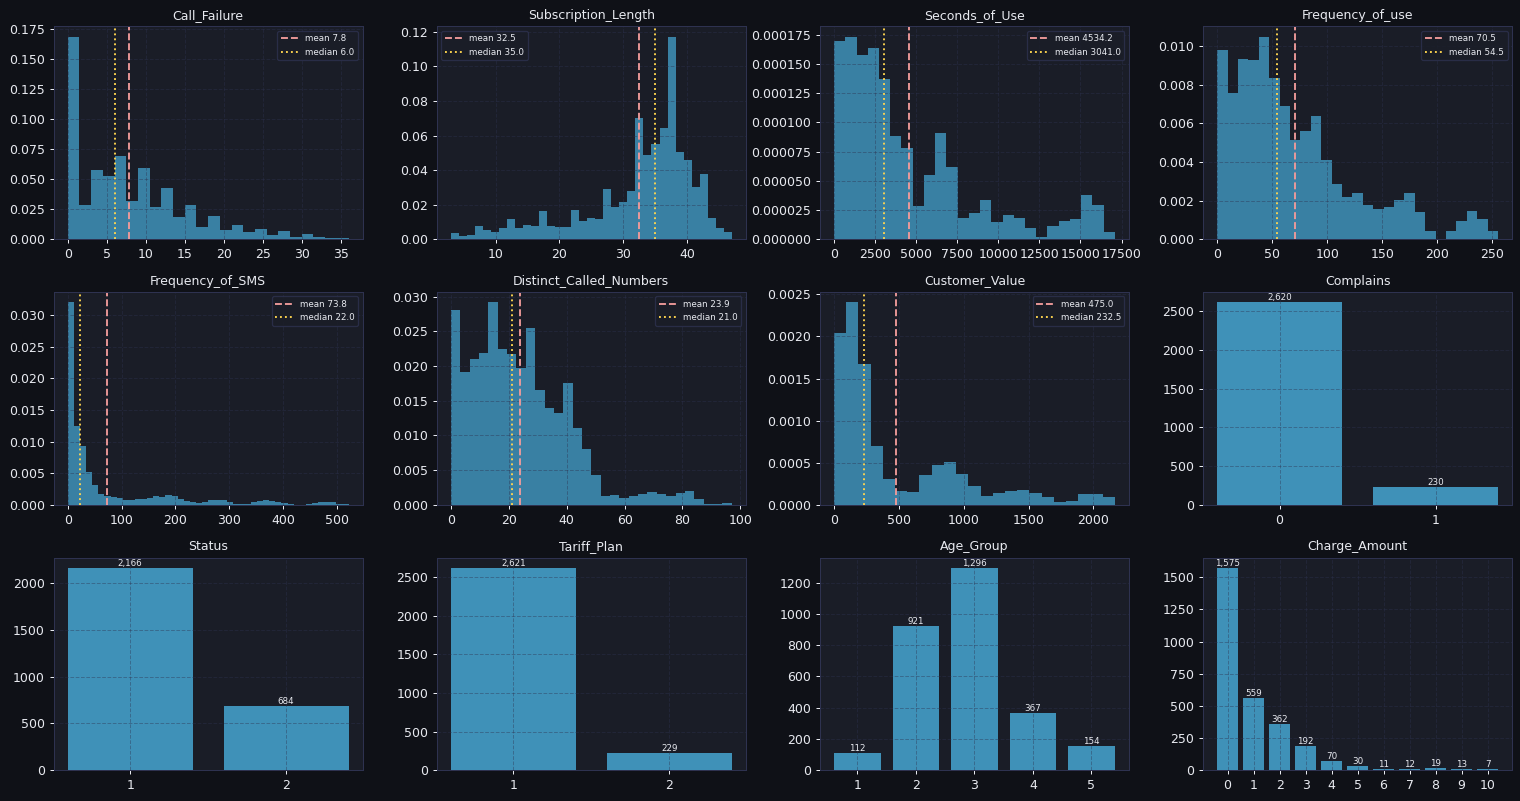


- Pemakaian dan `Call_Failure` condong ke kanan (skew 1.31 / 1.15 / 1.97 / 1.04 / 1.07); `Subscription_Length` skew negatif (-1.25), median 35 bulan.
- `Customer_Value` bimodal, tetapi sudah kita ketahui ia fungsi pasti pemakaian dan usia (FASE 2 B), jadi bentuknya bukan informasi baru.
- Kategorik sangat timpang: Complains = 1 (230, 8.1%), Tariff_Plan 2 (229, 8.0%), Status 2 (684, 24.0%), Charge_Amount = 0 (1,575, 55.3%).
- **Target:** churn 446 (15.6%) vs 2,404: rasio 1 : 5.4. Pada tingkat profil: 8 dari 50 (16%). Untuk pemodelan: jangan memakai akurasi; pakai PR-AUC/recall pada presisi tertentu; imbalance (mis. SMOTE) hanya di dalam fold latih, dan **tanpa** menyintesis dari baris yang bersaudara.


In [13]:
uni = pd.DataFrame({'mean': df[NUM].mean(), 'median': df[NUM].median(), 'std': df[NUM].std(),
                    'min': df[NUM].min(), 'max': df[NUM].max(), 'skew': df[NUM].apply(skew)}).round(2)
display(uni)

items = [('hist', c) for c in NUM] + [('bar', c) for c in CAT]
ncols = 4; nrows = int(np.ceil(len(items) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(17, 3.0 * nrows)); axes = axes.ravel()
for ax, (kind, c) in zip(axes, items):
    s = df[c]
    if kind == 'hist':
        ax.hist(s, bins='auto', color=C0, alpha=.6, density=True)
        ax.axvline(s.mean(), color=C1, ls='--', label=f'mean {s.mean():.1f}'); ax.axvline(s.median(), color=ACC, ls=':', label=f'median {s.median():.1f}')
        ax.legend(fontsize=7)
    else:
        vc = s.value_counts().sort_index(); ax.bar(vc.index.astype(str), vc.values, color=C0, alpha=.7)
        for i, v in enumerate(vc.values):
            ax.text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=7)
    ax.set_title(c, fontsize=10)
for ax in axes[len(items):]:
    ax.set_visible(False)
plt.tight_layout(); plt.show()

vc = {c: df[c].value_counts() for c in CAT}
md(f"""
- Pemakaian dan `Call_Failure` condong ke kanan (skew {uni.loc[S_, 'skew']:.2f} / {uni.loc[F_, 'skew']:.2f} / {uni.loc[SMS_, 'skew']:.2f} / {uni.loc[D_, 'skew']:.2f} / {uni.loc['Call_Failure', 'skew']:.2f}); `Subscription_Length` skew negatif ({uni.loc['Subscription_Length', 'skew']:.2f}), median {df.Subscription_Length.median():.0f} bulan.
- `Customer_Value` bimodal, tetapi sudah kita ketahui ia fungsi pasti pemakaian dan usia (FASE 2 B), jadi bentuknya bukan informasi baru.
- Kategorik sangat timpang: Complains = 1 ({vc['Complains'][1]}, {vc['Complains'][1] / N * 100:.1f}%), Tariff_Plan 2 ({vc['Tariff_Plan'][2]}, {vc['Tariff_Plan'][2] / N * 100:.1f}%), Status 2 ({vc['Status'][2]}, {vc['Status'][2] / N * 100:.1f}%), Charge_Amount = 0 ({vc['Charge_Amount'][0]:,}, {vc['Charge_Amount'][0] / N * 100:.1f}%).
- **Target:** churn {N_CHURN} ({BASE:.1f}%) vs {N - N_CHURN:,}: rasio 1 : {(N - N_CHURN) / N_CHURN:.1f}. Pada tingkat profil: {N_CHURN_SEEDS} dari {N_SEEDS} ({N_CHURN_SEEDS / N_SEEDS * 100:.0f}%). Untuk pemodelan: jangan memakai akurasi; pakai PR-AUC/recall pada presisi tertentu; imbalance (mis. SMOTE) hanya di dalam fold latih, dan **tanpa** menyintesis dari baris yang bersaudara.
""")

## Outlier (IQR)

Logika IQR dipertahankan, tetapi **p-value dihapus**: uji chi-square/Fisher pada baris mengasumsikan independensi yang tidak berlaku. Sebagai gantinya dilaporkan **berapa profil** yang menyumbang outlier, karena "outlier" yang berasal dari satu atau dua profil bukan bukti pola pelanggan.

,batas bawah,batas atas,n outlier,n profil,profil churn,churn outlier %,churn normal %,RR
Fitur,,,,,,,,
Call_Failure,-15.5,28.5,44,4,1,20.45,15.57,1.31
Subscription_Length,15.5,51.5,208,6,1,28.37,14.65,1.94
Seconds_of_Use,-6103.1,14061.9,189,4,0,0.00,16.76,0.00
Frequency_of_use,-74.0,198.0,118,3,0,0.00,16.33,0.00
Frequency_of_SMS,-114.5,209.5,333,9,0,0.00,17.72,0.00
Distinct_Called_Numbers,-23.5,68.5,82,2,0,0.00,16.11,0.00
Customer_Value,-891.3,1798.9,104,3,0,0.00,16.24,0.00


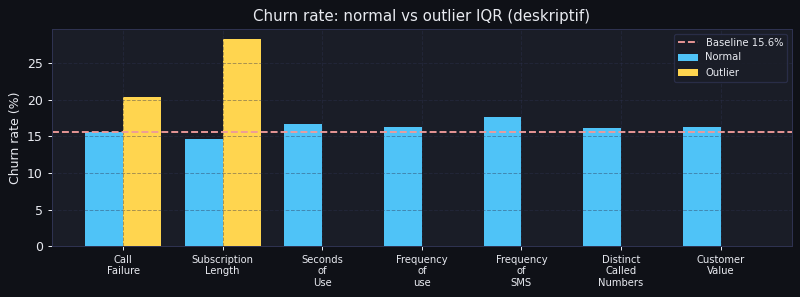


- Outlier atas pada `Seconds_of_Use` (n=189 dari 4 profil), `Frequency_of_use` (n=118 dari 3 profil), `Frequency_of_SMS` (n=333 dari 9 profil), `Distinct_Called_Numbers` (n=82 dari 2 profil), `Customer_Value` (n=104 dari 3 profil) **tidak mengandung churner**. Namun outlier-outlier itu hanya berasal dari **2-9 profil**, dan profil pemakaian-sangat-tinggi memang bukan profil churn. Ini bukan bukti dari ratusan pelanggan independen.
- `Subscription_Length`: 208 outlier (di bawah 15.5) berasal dari **hanya 6 profil**, dengan 1 profil churn; churn 28.4% dengan RR 1.94. Rapuh (lihat FASE 4).
- Keputusan: tidak ada baris atau kolom yang dibuang atau di-cap. Flag outlier manual tidak dibuat; model pohon dapat memotong sendiri.


In [14]:
def iqr_bounds(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return q1 - 1.5 * i, q3 + 1.5 * i

rows = []
for c in NUM:
    lo, hi = iqr_bounds(df[c]); m = (df[c] < lo) | (df[c] > hi)
    cr_o = df.loc[m, TARGET].mean() * 100 if m.any() else np.nan
    cr_n = df.loc[~m, TARGET].mean() * 100
    rows.append({'Fitur': c, 'batas bawah': round(lo, 1), 'batas atas': round(hi, 1), 'n outlier': int(m.sum()),
                 'n profil': int(df.loc[m, 'seed'].nunique()), 'profil churn': int(df.loc[m].groupby('seed').seed_churn.first().sum()) if m.any() else 0,
                 'churn outlier %': cr_o, 'churn normal %': cr_n, 'RR': cr_o / cr_n if m.any() and cr_n else np.nan})
out_df = pd.DataFrame(rows).set_index('Fitur'); display(out_df.round(2))

fig, ax = plt.subplots(figsize=(9, 3.4)); x = np.arange(len(NUM)); w = .38
ax.bar(x - w / 2, out_df['churn normal %'], w, color=C0, label='Normal'); ax.bar(x + w / 2, out_df['churn outlier %'].fillna(0), w, color=ACC, label='Outlier')
ax.axhline(BASE, color=C1, ls='--', label=f'Baseline {BASE:.1f}%'); ax.set_xticks(x); ax.set_xticklabels([c.replace('_', '\n') for c in NUM], fontsize=8)
ax.set_ylabel('Churn rate (%)'); ax.set_title('Churn rate: normal vs outlier IQR (deskriptif)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

zero_out = out_df[(out_df['n outlier'] > 0) & (out_df['churn outlier %'] == 0)]
sl = out_df.loc['Subscription_Length']
md(f"""
- Outlier atas pada {', '.join(f'`{c}` (n={int(r["n outlier"])} dari {int(r["n profil"])} profil)' for c, r in zero_out.iterrows())} **tidak mengandung churner**. Namun outlier-outlier itu hanya berasal dari **{int(zero_out['n profil'].min())}-{int(zero_out['n profil'].max())} profil**, dan profil pemakaian-sangat-tinggi memang bukan profil churn. Ini bukan bukti dari ratusan pelanggan independen.
- `Subscription_Length`: {int(sl['n outlier'])} outlier (di bawah {sl['batas bawah']}) berasal dari **hanya {int(sl['n profil'])} profil**, dengan {int(sl['profil churn'])} profil churn; churn {sl['churn outlier %']:.1f}% dengan RR {sl['RR']:.2f}. Rapuh (lihat FASE 4).
- Keputusan: tidak ada baris atau kolom yang dibuang atau di-cap. Flag outlier manual tidak dibuat; model pohon dapat memotong sendiri.
""")

# FASE 4: Hubungan Fitur dengan Churn

## A. Deskriptif tingkat baris

,AUC tunggal (jenis 1),arah,Spearman
Fitur,,,
Status,0.790,naik -> churn,0.493
Seconds_of_Use,0.786,naik -> loyal,-0.360
Customer_Value,0.781,naik -> loyal,-0.354
Frequency_of_use,0.767,naik -> loyal,-0.336
Distinct_Called_Numbers,0.731,naik -> loyal,-0.291
Complains,0.705,naik -> churn,0.546
Charge_Amount,0.678,naik -> loyal,-0.248
Frequency_of_SMS,0.670,naik -> loyal,-0.215
Tariff_Plan,0.540,naik -> loyal,-0.106


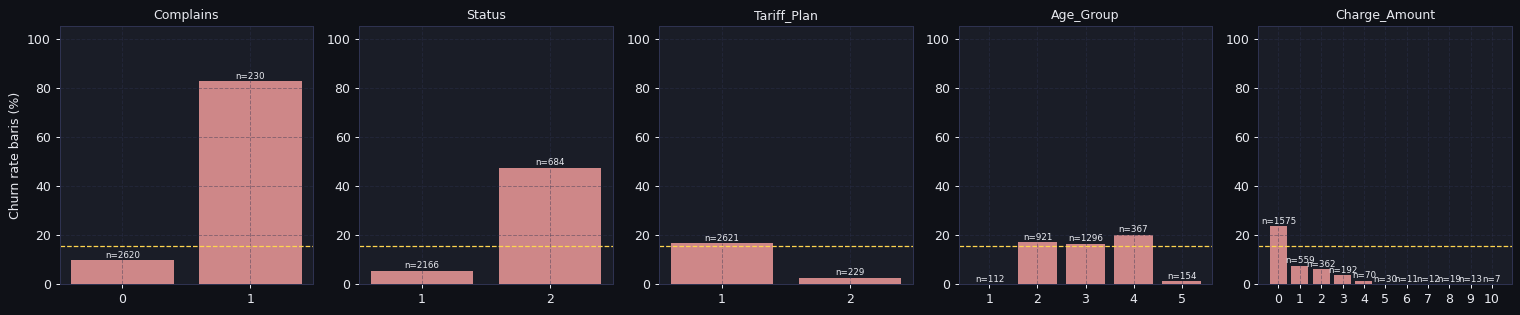

In [15]:
def auc_dir(x, y=df[TARGET]):
    a = roc_auc_score(y, x)
    return max(a, 1 - a), ('naik -> churn' if a > .5 else 'naik -> loyal')

tab = []
for c in FEATURES:
    a, arah = auc_dir(df[c])
    tab.append({'Fitur': c, 'AUC tunggal (jenis 1)': round(a, 3), 'arah': arah, 'Spearman': round(spearmanr(df[c], df[TARGET])[0], 3)})
auc_tab = pd.DataFrame(tab).set_index('Fitur').sort_values('AUC tunggal (jenis 1)', ascending=False)
display(auc_tab)

fig, axes = plt.subplots(1, len(CAT), figsize=(17, 3.6))
for ax, c in zip(axes, CAT):
    t = rate_table(df, c)
    ax.bar(t[c].astype(str), t.rate, color=C1, alpha=.85)
    for i, (r, n) in enumerate(zip(t.rate, t.n)):
        ax.text(i, r + 1, f'n={n}', ha='center', fontsize=7)
    ax.axhline(BASE, color=ACC, ls='--', lw=1); ax.set_title(c, fontsize=10); ax.set_ylim(0, 105)
axes[0].set_ylabel('Churn rate baris (%)')
plt.tight_layout(); plt.show()

## B. Uji ulang temuan kunci di tingkat profil

Untuk tiap klaim "kelompok X berisiko churn", dibandingkan:
1. **Churn rate baris** dengan CI Wilson **naif** (mengira baris independen);
2. **CI bootstrap-klaster**: resampling **profil**, bukan baris;
3. **Uji tingkat profil**: apakah *proporsi baris berstatus X* dalam sebuah profil lebih tinggi pada profil churn dibanding profil non-churn (Mann-Whitney), dengan koreksi Benjamini-Hochberg.

Klaim dianggap **tahan** hanya bila p (BH) < 0.05 **dan** CI klaster tidak memuat baseline.

In [16]:
CLAIMS = {
    'Complains = 1': df.Complains == 1,
    'Status = 2 (non-aktif)': df.Status == 2,
    'Tariff_Plan = 2 (contractual)': df.Tariff_Plan == 2,
    'Usia 15 atau 55 (Age_Group 1/5)': df.Age_Group.isin([1, 5]),
    'Tenure <= 12 bulan': df.Subscription_Length <= 12,
    'Seconds_of_Use kuartil terendah': pd.qcut(df[S_], 4, labels=False) == 0,
    'Seconds_of_Use kuartil tertinggi': pd.qcut(df[S_], 4, labels=False) == 3,
    'Distinct_Called_Numbers kuartil terendah': pd.qcut(df[D_], 4, labels=False) == 0,
    'Charge_Amount = 0': df.Charge_Amount == 0,
    'Call_Failure kuartil tertinggi': pd.qcut(df.Call_Failure, 4, labels=False) == 3,
}
n_all_s = df.groupby('seed').size().reindex(range(N_SEEDS), fill_value=0).values
is_churn_seed = seed_tab.seed_churn.reindex(range(N_SEEDS)).values == 1

def seed_counts(mask):
    g = df[mask].groupby('seed')[TARGET].agg(['size', 'sum']).reindex(range(N_SEEDS), fill_value=0)
    return g['size'].values, g['sum'].values

def cluster_boot_ci(mask, B=3000):
    n_s, c_s = seed_counts(mask); idx = rng.integers(0, N_SEEDS, (B, N_SEEDS))
    n, c = n_s[idx].sum(1), c_s[idx].sum(1); ok = n > 0
    return np.percentile(c[ok] / n[ok], [2.5, 97.5]) * 100

rows = []
for name, m in CLAIMS.items():
    m = pd.Series(np.asarray(m), index=df.index)
    n_s, c_s = seed_counts(m); share = n_s / n_all_s
    k, n = int(c_s.sum()), int(n_s.sum()); lo_n, hi_n = wilson(k, n); lo_c, hi_c = cluster_boot_ci(m)
    try:
        p = mannwhitneyu(share[is_churn_seed], share[~is_churn_seed], alternative='two-sided')[1]
    except ValueError:
        p = 1.0
    rows.append({'klaim': name, 'n baris': n, 'n profil': int((n_s > 0).sum()), 'churn baris %': k / n * 100,
                 'CI naif %': f'{lo_n * 100:.1f}-{hi_n * 100:.1f}', 'CI klaster %': f'{lo_c:.1f}-{hi_c:.1f}',
                 'lo_c': lo_c, 'hi_c': hi_c, 'p profil': p})
claims_df = pd.DataFrame(rows).set_index('klaim')
claims_df['p (BH)'] = multipletests(claims_df['p profil'].values, method='fdr_bh')[1]
claims_df['tahan uji klaster?'] = np.where((claims_df['p (BH)'] < 0.05) & ((claims_df.lo_c > BASE) | (claims_df.hi_c < BASE)), 'TAHAN',
                                  np.where((claims_df['p (BH)'] < 0.05) | (claims_df.lo_c > BASE) | (claims_df.hi_c < BASE), 'sebagian', 'tidak tahan'))
show = claims_df[['n baris', 'n profil', 'churn baris %', 'CI naif %', 'CI klaster %', 'p profil', 'p (BH)', 'tahan uji klaster?']]
display(show.style.format({'churn baris %': '{:.1f}', 'p profil': '{:.4f}', 'p (BH)': '{:.4f}'}))
print(f'Baseline churn baris: {BASE:.1f}%  |  profil churn: {N_CHURN_SEEDS} dari {N_SEEDS}')

,n baris,n profil,churn baris %,CI naif %,CI klaster %,p profil,p (BH),tahan uji klaster?
klaim,,,,,,,,
Complains = 1,230,21,82.6,77.2-87.0,57.0-95.1,0.0000,0.0000,TAHAN
Status = 2 (non-aktif),684,14,47.5,43.8-51.3,20.5-75.1,0.0001,0.0003,TAHAN
Tariff_Plan = 2 (contractual),229,13,2.6,1.2-5.6,0.0-7.1,0.2644,0.3305,sebagian
Usia 15 atau 55 (Age_Group 1/5),266,9,0.8,0.2-2.7,0.0-2.2,0.1608,0.2297,sebagian
Tenure <= 12 bulan,132,6,39.4,31.5-47.9,0.0-88.9,0.8881,0.8881,tidak tahan
Seconds_of_Use kuartil terendah,713,22,34.6,31.2-38.2,11.8-59.3,0.0248,0.0620,tidak tahan
Seconds_of_Use kuartil tertinggi,711,16,0.0,0.0-0.5,0.0-0.0,0.1404,0.2297,sebagian
Distinct_Called_Numbers kuartil terendah,765,34,29.7,26.5-33.0,10.1-50.8,0.0526,0.1052,tidak tahan
Charge_Amount = 0,1575,49,23.7,21.7-25.9,10.3-37.9,0.0117,0.0388,sebagian


Baseline churn baris: 15.6%  |  profil churn: 8 dari 50


In [17]:
tahan = claims_df.index[claims_df['tahan uji klaster?'] == 'TAHAN'].tolist()
tdk = claims_df.index[claims_df['tahan uji klaster?'] == 'tidak tahan'].tolist()
sebagian = claims_df.index[claims_df['tahan uji klaster?'] == 'sebagian'].tolist()
c = claims_df
md(f"""
**Hasil.**
- **Tahan** ({len(tahan)}): {'; '.join(tahan) if tahan else '-'}.
- **Sebagian** ({len(sebagian)}): {'; '.join(sebagian) if sebagian else '-'}.
- **Tidak tahan** ({len(tdk)}): {'; '.join(tdk) if tdk else '-'}.
- Contoh dampaknya: `Usia 15/55` terlihat sangat signifikan di tingkat baris ({c.loc['Usia 15 atau 55 (Age_Group 1/5)', 'n baris']} baris, churn {c.loc['Usia 15 atau 55 (Age_Group 1/5)', 'churn baris %']:.1f}% vs baseline {BASE:.1f}%), tetapi ia hanya berasal dari **{c.loc['Usia 15 atau 55 (Age_Group 1/5)', 'n profil']} profil**; p tingkat profil (BH) = {c.loc['Usia 15 atau 55 (Age_Group 1/5)', 'p (BH)']:.2f}. `Tenure <= 12 bulan`: {c.loc['Tenure <= 12 bulan', 'n baris']} baris dari **{c.loc['Tenure <= 12 bulan', 'n profil']} profil**, CI klaster {c.loc['Tenure <= 12 bulan', 'CI klaster %']}% (hampir seluruh rentang), p (BH) = {c.loc['Tenure <= 12 bulan', 'p (BH)']:.2f}.
- Dibandingkan CI naif, CI klaster **jauh lebih lebar**, mis. `Complains = 1`: naif {c.loc['Complains = 1', 'CI naif %']}% vs klaster {c.loc['Complains = 1', 'CI klaster %']}%.
- **Peringatan:** dengan hanya {N_CHURN_SEEDS} profil churn, daya uji tingkat profil rendah. "Tidak tahan" berarti *tidak ada bukti yang memadai*, bukan "terbukti tidak berpengaruh".
""")


**Hasil.**
- **Tahan** (2): Complains = 1; Status = 2 (non-aktif).
- **Sebagian** (4): Tariff_Plan = 2 (contractual); Usia 15 atau 55 (Age_Group 1/5); Seconds_of_Use kuartil tertinggi; Charge_Amount = 0.
- **Tidak tahan** (4): Tenure <= 12 bulan; Seconds_of_Use kuartil terendah; Distinct_Called_Numbers kuartil terendah; Call_Failure kuartil tertinggi.
- Contoh dampaknya: `Usia 15/55` terlihat sangat signifikan di tingkat baris (266 baris, churn 0.8% vs baseline 15.6%), tetapi ia hanya berasal dari **9 profil**; p tingkat profil (BH) = 0.23. `Tenure <= 12 bulan`: 132 baris dari **6 profil**, CI klaster 0.0-88.9% (hampir seluruh rentang), p (BH) = 0.89.
- Dibandingkan CI naif, CI klaster **jauh lebih lebar**, mis. `Complains = 1`: naif 77.2-87.0% vs klaster 57.0-95.1%.
- **Peringatan:** dengan hanya 8 profil churn, daya uji tingkat profil rendah. "Tidak tahan" berarti *tidak ada bukti yang memadai*, bukan "terbukti tidak berpengaruh".


In [18]:
SEED_FEATS = {'Seconds_of_Use': 'Seconds', 'Frequency_of_use': 'Frequency', 'Frequency_of_SMS': 'SMS',
              'Distinct_Called_Numbers': 'Distinct', 'Subscription_Length': 'Tenure', 'Call_Failure': 'Call_Failure'}
rows = []
for nm, col in SEED_FEATS.items():
    a_ = seed_tab.loc[seed_tab.seed_churn == 1, col]; b_ = seed_tab.loc[seed_tab.seed_churn == 0, col]
    u_, p_ = mannwhitneyu(a_, b_, alternative='two-sided'); auc_ = u_ / (len(a_) * len(b_))
    rows.append({'fitur': nm, 'median profil churn': a_.median(), 'median profil non-churn': b_.median(), 'AUC tingkat profil': max(auc_, 1 - auc_), 'p': p_})
seed_cmp = pd.DataFrame(rows).set_index('fitur'); seed_cmp['p (BH)'] = multipletests(seed_cmp.p.values, method='fdr_bh')[1]
display(seed_cmp.style.format({'median profil churn': '{:,.1f}', 'median profil non-churn': '{:,.1f}', 'AUC tingkat profil': '{:.2f}', 'p': '{:.3f}', 'p (BH)': '{:.3f}'}))
usage_raw = seed_cmp.index[seed_cmp.p < 0.05].tolist(); usage_bh = seed_cmp.index[seed_cmp['p (BH)'] < 0.05].tolist()
md(f"""
**Fitur numerik pada tingkat profil** ({N_CHURN_SEEDS} profil churn vs {N_SEEDS - N_CHURN_SEEDS} non-churn; satuan = median tiap profil).
- Median profil churn lebih rendah pada pemakaian (Seconds {seed_cmp.loc['Seconds_of_Use', 'median profil churn']:,.0f} vs {seed_cmp.loc['Seconds_of_Use', 'median profil non-churn']:,.0f}). p mentah < 0.05: {', '.join(usage_raw) if usage_raw else '-'}; **setelah koreksi BH (6 uji): {', '.join(usage_bh) if usage_bh else 'tidak ada'}**.
- `Subscription_Length` dan `Call_Failure` tidak membedakan profil churn dari non-churn (p = {seed_cmp.loc['Subscription_Length', 'p']:.2f} dan {seed_cmp.loc['Call_Failure', 'p']:.2f}).
- Dengan {N_CHURN_SEEDS} profil positif, daya uji rendah: arah pemakaian-rendah konsisten dengan intuisi dan dengan tabel klaim di atas, tetapi **buktinya terbatas**.
""")

,median profil churn,median profil non-churn,AUC tingkat profil,p,p (BH)
fitur,,,,,
Seconds_of_Use,"1,221.0","3,471.5",0.78,0.012,0.066
Frequency_of_use,30.0,60.5,0.74,0.032,0.066
Frequency_of_SMS,9.5,20.0,0.63,0.239,0.358
Distinct_Called_Numbers,11.5,23.0,0.74,0.033,0.066
Subscription_Length,36.0,36.5,0.59,0.421,0.505
Call_Failure,6.0,6.0,0.53,0.781,0.781



**Fitur numerik pada tingkat profil** (8 profil churn vs 42 non-churn; satuan = median tiap profil).
- Median profil churn lebih rendah pada pemakaian (Seconds 1,221 vs 3,472). p mentah < 0.05: Seconds_of_Use, Frequency_of_use, Distinct_Called_Numbers; **setelah koreksi BH (6 uji): tidak ada**.
- `Subscription_Length` dan `Call_Failure` tidak membedakan profil churn dari non-churn (p = 0.42 dan 0.78).
- Dengan 8 profil positif, daya uji rendah: arah pemakaian-rendah konsisten dengan intuisi dan dengan tabel klaim di atas, tetapi **buktinya terbatas**.


### Pola tenure dan usia (deskriptif, jangan ditafsirkan sebagai bukti)

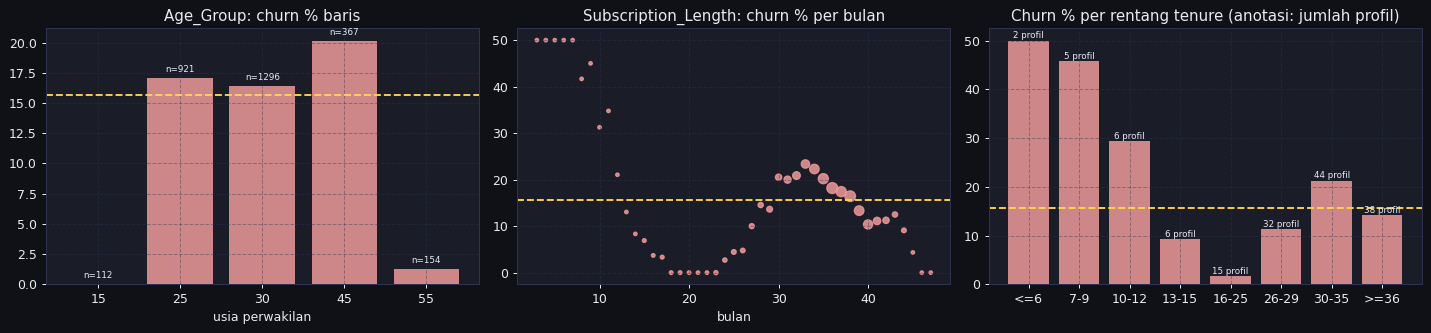

Pola U-terbalik pada usia dan lonjakan di tenure pendek **terlihat jelas di tingkat baris**, tetapi anotasi jumlah profil menunjukkan tiap batang hanya mewakili segelintir profil. Dari tabel klaim di atas, polanya tidak tahan uji klaster. Plot ini dibiarkan sebagai deskripsi data, **bukan dasar keputusan fitur**.

In [19]:
TEN_BINS = [0, 6, 9, 12, 15, 25, 29, 35, np.inf]
TEN_LABELS = ['<=6', '7-9', '10-12', '13-15', '16-25', '26-29', '30-35', '>=36']
df['Tenure_bin'] = pd.cut(df.Subscription_Length, TEN_BINS, labels=TEN_LABELS)
age_t = rate_table(df, 'Age_Group'); age_t['usia'] = age_t.Age_Group.map(AGE_VALUE)
by_val = df.groupby('Subscription_Length')[TARGET].agg(['mean', 'count'])
ten_seeds = df.groupby('Tenure_bin', observed=True).seed.nunique()

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].bar(age_t.usia.astype(str), age_t.rate, color=C1, alpha=.85)
for i, (n, r) in enumerate(zip(age_t.n, age_t.rate)):
    axes[0].text(i, r + .5, f'n={n}', ha='center', fontsize=7)
axes[0].axhline(BASE, color=ACC, ls='--'); axes[0].set_title('Age_Group: churn % baris'); axes[0].set_xlabel('usia perwakilan')
axes[1].scatter(by_val.index, by_val['mean'] * 100, s=np.clip(by_val['count'] / 3, 8, 120), color=C1, alpha=.85)
axes[1].axhline(BASE, color=ACC, ls='--'); axes[1].set_title('Subscription_Length: churn % per bulan'); axes[1].set_xlabel('bulan')
tr = rate_table(df, 'Tenure_bin'); axes[2].bar(tr.Tenure_bin.astype(str), tr.rate, color=C1, alpha=.85)
for i, (b, r) in enumerate(zip(tr.Tenure_bin, tr.rate)):
    axes[2].text(i, r + .5, f'{int(ten_seeds[b])} profil', ha='center', fontsize=7)
axes[2].axhline(BASE, color=ACC, ls='--'); axes[2].set_title('Churn % per rentang tenure (anotasi: jumlah profil)')
plt.tight_layout(); plt.show()
md("Pola U-terbalik pada usia dan lonjakan di tenure pendek **terlihat jelas di tingkat baris**, tetapi anotasi jumlah profil menunjukkan tiap batang hanya mewakili segelintir profil. Dari tabel klaim di atas, polanya tidak tahan uji klaster. Plot ini dibiarkan sebagai deskripsi data, **bukan dasar keputusan fitur**.")

## C. Struktur dan confounding (fakta struktural)

Charge_Amount,0,1,2,3,4,5,6,7,8,9,10
Status,,,,,,,,,,,
Status 1,891,559,362,192,70,30,11,12,19,13,7
Status 2,684,0,0,0,0,0,0,0,0,0,0


Status,Status 1,Status 2
Tariff_Plan,,
Plan 1,1938,683
Plan 2,228,1



- **Seluruh 684 baris Status 2 memiliki Charge_Amount = 0** (dari 14 profil). Ini fakta struktural yang konsisten di seluruh profil: `Charge_Amount = 0` memuat Status 2 sebagai bagiannya, sehingga efek "Charge 0 → churn" adalah efek Status. Charge_Amount tidak perlu diinterpretasikan terpisah.
- **228 dari 229 baris Plan 2 berstatus 1**, dengan pemakaian lebih tinggi (Seconds rata-rata 6,350 vs 4,376); keunggulan Plan 2 tercampur dengan Status dan pemakaian, dan hanya berasal dari beberapa profil.


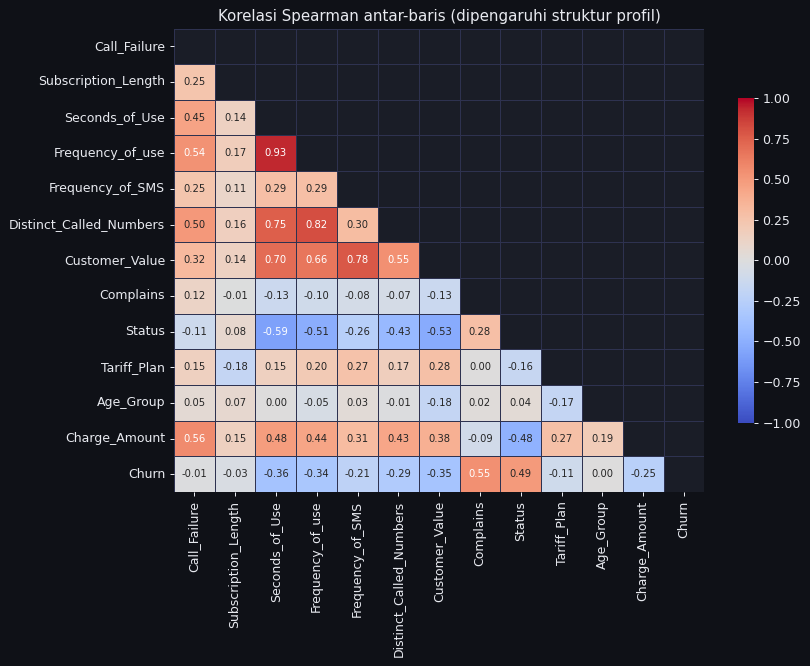

,VIF (semua),VIF (tanpa Customer_Value)
Customer_Value,50.0,NaN
Frequency_of_SMS,39.7,1.2
Seconds_of_Use,21.6,14.0
Frequency_of_use,18.3,18.2
Charge_Amount,3.2,3.1
Call_Failure,2.9,2.9
Distinct_Called_Numbers,2.4,2.4
Age_Group,2.1,1.2
Status,1.8,1.8
Tariff_Plan,1.6,1.5



VIF tertinggi `Customer_Value` (50) dan `Frequency_of_SMS` (40); setelah Customer_Value dikeluarkan, VIF SMS turun menjadi 1.2. Itu konsisten dengan rumus pasti di FASE 2 B. `Seconds_of_Use` dan `Frequency_of_use` tetap sangat berkorelasi (Spearman 0.93); bagian dari rumus Customer_Value juga.


In [20]:
ct_sc = pd.crosstab(df.Status, df.Charge_Amount)
display(ct_sc.rename(index={1: 'Status 1', 2: 'Status 2'}))
plan_by_status = pd.crosstab(df.Tariff_Plan, df.Status)
display(plan_by_status.rename(index={1: 'Plan 1', 2: 'Plan 2'}, columns={1: 'Status 1', 2: 'Status 2'}))
plan_profile = df.groupby('Tariff_Plan')[[S_, 'Charge_Amount']].mean().round(1)
st2_seeds = df[df.Status == 2].seed.nunique()
md(f"""
- **Seluruh {int((df.Status == 2).sum())} baris Status 2 memiliki Charge_Amount = 0** (dari {st2_seeds} profil). Ini fakta struktural yang konsisten di seluruh profil: `Charge_Amount = 0` memuat Status 2 sebagai bagiannya, sehingga efek "Charge 0 → churn" adalah efek Status. Charge_Amount tidak perlu diinterpretasikan terpisah.
- **{int(plan_by_status.loc[2, 1])} dari {int(plan_by_status.loc[2].sum())} baris Plan 2 berstatus 1**, dengan pemakaian lebih tinggi (Seconds rata-rata {plan_profile.loc[2, S_]:,.0f} vs {plan_profile.loc[1, S_]:,.0f}); keunggulan Plan 2 tercampur dengan Status dan pemakaian, dan hanya berasal dari beberapa profil.
""")

corr = df[FEATURES + [TARGET]].corr(method='spearman')
fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            linewidths=.4, linecolor=GRID, annot_kws={'size': 8}, ax=ax, cbar_kws={'shrink': .7})
ax.set_title('Korelasi Spearman antar-baris (dipengaruhi struktur profil)'); ax.grid(False)
plt.tight_layout(); plt.show()

def vif_table(cols):
    Xv = add_constant(df[cols].astype(float))
    return pd.Series([variance_inflation_factor(Xv.values, i) for i in range(Xv.shape[1])], index=Xv.columns).drop('const')
v_all = vif_table(FEATURES); v_nocv = vif_table([c for c in FEATURES if c != 'Customer_Value'])
display(pd.DataFrame({'VIF (semua)': v_all.round(1), 'VIF (tanpa Customer_Value)': v_nocv.round(1)}).sort_values('VIF (semua)', ascending=False))
md(f"""
VIF tertinggi `Customer_Value` ({v_all['Customer_Value']:.0f}) dan `Frequency_of_SMS` ({v_all['Frequency_of_SMS']:.0f}); setelah Customer_Value dikeluarkan, VIF SMS turun menjadi {v_nocv['Frequency_of_SMS']:.1f}. Itu konsisten dengan rumus pasti di FASE 2 B. `Seconds_of_Use` dan `Frequency_of_use` tetap sangat berkorelasi (Spearman {df[S_].corr(df[F_], method='spearman'):.2f}); bagian dari rumus Customer_Value juga.
""")

# FASE 5: Diagnostik Berbasis Model (per profil)

> **Banner: diagnostik, bukan evaluasi final.** Semua AUC di bagian ini dihitung *out-of-fold* dengan `StratifiedGroupKFold` (seluruh baris satu profil selalu di fold yang sama), dirata-ratakan dari 4 ulangan acak. Variasi antar-ulangan hanya mencerminkan acakan pembagian; **ketidakpastian akibat sedikitnya profil positif jauh lebih besar** dan ditunjukkan sebagai CI bootstrap-profil bila relevan.

## A. Ablasi fitur

In [21]:
def ablate(drop, repeats=4):
    cols = [c for c in FEATURES if c not in drop]
    P, a, ap = oof_predict(cols, True, repeats); return a, ap

base_a, base_ap = a_grp, ap_grp           # model semua fitur (dihitung di FASE 2 E, 4 ulangan)
rows = []
variants = {f'- {c}': [c] for c in FEATURES}
variants.update({'- {Status, Complains}': ['Status', 'Complains'],
                 '- {Customer_Value, Charge_Amount, Tariff_Plan, Frequency_of_SMS}': ['Customer_Value', 'Charge_Amount', 'Tariff_Plan', 'Frequency_of_SMS'],
                 '- {Subscription_Length, Age_Group, Charge_Amount}': ['Subscription_Length', 'Age_Group', 'Charge_Amount']})
for name, drop in variants.items():
    a, ap = ablate(drop); d = a - base_a; se = d.std(ddof=1) / np.sqrt(len(d))
    verdict = 'penting (membuang merugikan)' if d.mean() + 2 * se < 0 else ('membuang menguntungkan' if d.mean() - 2 * se > 0 else 'tidak terbedakan')
    rows.append({'varian': name, 'AUC per profil': a.mean(), 'Δ AUC': d.mean(), 'SE antar-ulangan': se, 'verdict': verdict})
abl = pd.DataFrame(rows).set_index('varian').sort_values('Δ AUC')
print(f'AUC dasar semua fitur (per profil): {base_a.mean():.3f}')
display(abl.style.format({'AUC per profil': '{:.3f}', 'Δ AUC': '{:+.4f}', 'SE antar-ulangan': '{:.4f}'}))

AUC dasar semua fitur (per profil): 0.790


,AUC per profil,Δ AUC,SE antar-ulangan,verdict
varian,,,,
"- {Status, Complains}",0.628,-0.1616,0.0039,penting (membuang merugikan)
- Complains,0.681,-0.1085,0.0064,penting (membuang merugikan)
- Status,0.759,-0.0301,0.0026,penting (membuang merugikan)
- Call_Failure,0.785,-0.0042,0.0048,tidak terbedakan
"- {Customer_Value, Charge_Amount, Tariff_Plan, Frequency_of_SMS}",0.787,-0.0024,0.0014,tidak terbedakan
- Subscription_Length,0.787,-0.0023,0.0046,tidak terbedakan
- Frequency_of_SMS,0.790,-0.0001,0.0019,tidak terbedakan
- Tariff_Plan,0.790,-0.0000,0.0000,tidak terbedakan
- Charge_Amount,0.791,+0.0017,0.0020,tidak terbedakan


In [22]:
imp = abl[abl.verdict.str.startswith('penting')].index.tolist()
better = abl[abl.verdict.str.startswith('membuang menguntungkan')].index.tolist()
md(f"""
**Hasil (diagnostik).**
- **Penting**: {', '.join(f'`{i[2:]}` ({abl.loc[i, "Δ AUC"]:+.3f})' for i in imp) if imp else '-'}.
- **Membuang justru menguntungkan** (fitur ini menambah noise pada CV per profil): {', '.join(f'`{i[2:]}` ({abl.loc[i, "Δ AUC"]:+.3f})' for i in better) if better else '-'}.
- Pada CV acak (versi pertama), membuang `Subscription_Length`, `Age_Group`, `Call_Failure` merugikan; **pada CV per profil kesimpulan itu hilang atau terbalik**. Alasannya: fitur ber-ICC tinggi (tenure, usia, call failure) adalah *sidik jari profil*, dan pada CV acak sidik jari itu membantu model mengingat profil. Rekomendasi drop dari versi pertama ("pertahankan Age_Group dan Subscription_Length") **ditarik**.
- Kekuatan sebenarnya berasal dari `Complains` dan `Status`. Catatan: `Complains` hampir mekanis terhadap label (FASE 2 D), sehingga pentingnya perlu dibaca dengan hati-hati.
""")


**Hasil (diagnostik).**
- **Penting**: `{Status, Complains}` (-0.162), `Complains` (-0.108), `Status` (-0.030).
- **Membuang justru menguntungkan** (fitur ini menambah noise pada CV per profil): `Customer_Value` (+0.006), `Distinct_Called_Numbers` (+0.011), `Seconds_of_Use` (+0.012), `{Subscription_Length, Age_Group, Charge_Amount}` (+0.022), `Age_Group` (+0.024).
- Pada CV acak (versi pertama), membuang `Subscription_Length`, `Age_Group`, `Call_Failure` merugikan; **pada CV per profil kesimpulan itu hilang atau terbalik**. Alasannya: fitur ber-ICC tinggi (tenure, usia, call failure) adalah *sidik jari profil*, dan pada CV acak sidik jari itu membantu model mengingat profil. Rekomendasi drop dari versi pertama ("pertahankan Age_Group dan Subscription_Length") **ditarik**.
- Kekuatan sebenarnya berasal dari `Complains` dan `Status`. Catatan: `Complains` hampir mekanis terhadap label (FASE 2 D), sehingga pentingnya perlu dibaca dengan hati-hati.


## B. Sensitivitas: bergantung pada Status dan Complains?

In [23]:
MINIMAL = {
    'Status + Complains': ['Status', 'Complains'],
    'Status + Complains + Seconds_of_Use': ['Status', 'Complains', S_],
    'Hanya pemakaian (4 fitur)': [S_, F_, SMS_, D_],
    'Hanya Status': ['Status'], 'Hanya Complains': ['Complains'],
    'Semua tanpa Complains': [c for c in FEATURES if c != 'Complains'],
    'Semua tanpa Status': [c for c in FEATURES if c != 'Status'],
    'Semua tanpa Status & Complains': [c for c in FEATURES if c not in ('Status', 'Complains')],
    'Semua fitur': FEATURES,
}
rows = []; P_store = {}
for name, cols in MINIMAL.items():
    P, a, ap = oof_predict(cols, True, 4); P_store[name] = P.mean(0)
    ci = seed_boot_ci(lambda idx, p=P.mean(0): roc_auc_score(df[TARGET].values[idx], p[idx]), B=200)
    rows.append({'model': name, 'n fitur': len(cols), 'AUC per profil': a.mean(), 'CI profil 95%': f'{ci[0]:.2f}-{ci[1]:.2f}', 'PR-AUC': ap.mean()})
sens = pd.DataFrame(rows).set_index('model'); display(sens.round(3))

best_simple = sens.loc[['Status + Complains', 'Status + Complains + Seconds_of_Use']]['AUC per profil'].idxmax()
md(f"""
- Model minimal `Status + Complains` mencapai AUC **{sens.loc['Status + Complains', 'AUC per profil']:.3f}**, **lebih tinggi daripada semua fitur** ({sens.loc['Semua fitur', 'AUC per profil']:.3f}). Pada data sebesar ini, menambah fitur lebih banyak mencemari ketimbang membantu.
- Tanpa `Complains`: {sens.loc['Semua tanpa Complains', 'AUC per profil']:.3f}; tanpa `Status`: {sens.loc['Semua tanpa Status', 'AUC per profil']:.3f}; tanpa keduanya: **{sens.loc['Semua tanpa Status & Complains', 'AUC per profil']:.3f}**; hanya pemakaian: {sens.loc['Hanya pemakaian (4 fitur)', 'AUC per profil']:.3f}. Performa sangat bergantung pada dua fitur yang paling dekat dengan "keadaan akhir" pelanggan.
- CI bootstrap-profil lebar (lihat kolom). Perbedaan antar-model yang kecil tidak boleh dibaca sebagai peringkat.
- Untuk pemodelan: jadikan `{best_simple}` sebagai **baseline yang harus dikalahkan**, dan laporkan juga model tanpa `Status`/`Complains` bila tujuannya memprediksi churn *sebelum* sinyal-sinyal itu muncul.
""")

,n fitur,AUC per profil,CI profil 95%,PR-AUC
model,,,,
Status + Complains,2,0.824,0.67-0.93,0.575
Status + Complains + Seconds_of_Use,3,0.828,0.68-0.93,0.544
Hanya pemakaian (4 fitur),4,0.649,0.48-0.78,0.197
Hanya Status,1,0.701,0.40-0.85,0.328
Hanya Complains,1,0.595,0.36-0.65,0.411
Semua tanpa Complains,11,0.681,0.45-0.84,0.245
Semua tanpa Status,11,0.759,0.63-0.87,0.405
Semua tanpa Status & Complains,10,0.628,0.46-0.78,0.194
Semua fitur,12,0.790,0.62-0.92,0.432



- Model minimal `Status + Complains` mencapai AUC **0.824**, **lebih tinggi daripada semua fitur** (0.790). Pada data sebesar ini, menambah fitur lebih banyak mencemari ketimbang membantu.
- Tanpa `Complains`: 0.681; tanpa `Status`: 0.759; tanpa keduanya: **0.628**; hanya pemakaian: 0.649. Performa sangat bergantung pada dua fitur yang paling dekat dengan "keadaan akhir" pelanggan.
- CI bootstrap-profil lebar (lihat kolom). Perbedaan antar-model yang kecil tidak boleh dibaca sebagai peringkat.
- Untuk pemodelan: jadikan `Status + Complains + Seconds_of_Use` sebagai **baseline yang harus dikalahkan**, dan laporkan juga model tanpa `Status`/`Complains` bila tujuannya memprediksi churn *sebelum* sinyal-sinyal itu muncul.


## C. Regresi logistik dengan galat-baku klaster

In [24]:
Xr = pd.DataFrame({'log_Seconds': np.log1p(df[S_]), 'Status2': (df.Status == 2).astype(int), 'Complains': df.Complains,
                   'Call_Failure': df.Call_Failure, 'Tenure_le12': (df.Subscription_Length <= 12).astype(int),
                   'Usia_15_55': df.Age_Group.isin([1, 5]).astype(int), 'Plan2': (df.Tariff_Plan == 2).astype(int)})
glm = sm.GLM(df[TARGET], sm.add_constant(Xr), family=sm.families.Binomial())
m_naive = glm.fit(); m_clust = glm.fit(cov_type='cluster', cov_kwds={'groups': df.seed.values})
ci_n, ci_c = np.exp(m_naive.conf_int()), np.exp(m_clust.conf_int())
lg = pd.DataFrame({'OR': np.exp(m_naive.params), 'CI naif': [f'{a:.2f}-{b:.2f}' for a, b in zip(ci_n[0], ci_n[1])], 'p naif': m_naive.pvalues,
                   'CI klaster': [f'{a:.2f}-{b:.2f}' for a, b in zip(ci_c[0], ci_c[1])], 'p klaster': m_clust.pvalues}).drop('const')
display(lg.style.format({'OR': '{:.2f}', 'p naif': '{:.1e}', 'p klaster': '{:.3f}'}))
cf_row = lg.loc['Call_Failure']
sig_cl = lg.index[lg['p klaster'] < 0.05].tolist()
nonsig_cl = lg.index[lg['p klaster'] >= 0.05].tolist()
md(f"""
- Dengan galat-baku **klaster** (per profil), yang tetap signifikan (p < 0.05): {', '.join('`' + v + '`' for v in sig_cl)}; tidak signifikan: {', '.join('`' + v + '`' for v in nonsig_cl)}. **CI sangat lebar** (OR `Complains` {lg.loc['Complains', 'CI klaster']}; `Status2` {lg.loc['Status2', 'CI klaster']}).
- `Call_Failure`: OR {cf_row['OR']:.3f}, p naif {cf_row['p naif']:.1e} (di versi pertama dianggap *suppressor* yang signifikan), tetapi **p klaster = {cf_row['p klaster']:.2f}**: klaim suppressor **ditarik**.
- `Tenure_le12` (p klaster {lg.loc['Tenure_le12', 'p klaster']:.3f}) dan `Usia_15_55` (p klaster {lg.loc['Usia_15_55', 'p klaster']:.3f}) tampak signifikan di sini, **tetapi tidak di uji tingkat profil** (FASE 4 B), karena keduanya bertumpu pada sangat sedikit profil. Galat-baku klaster dengan hanya {N_SEEDS} klaster dan {N_CHURN_SEEDS} klaster positif **terkenal terlalu optimistis**, jadi hasil ini bukan bukti tambahan.
""")

,OR,CI naif,p naif,CI klaster,p klaster
log_Seconds,0.74,0.69-0.80,9.5e-16,0.57-0.96,0.023
Status2,10.18,7.12-14.53,2.9e-37,2.00-51.89,0.005
Complains,39.19,23.84-64.41,2.0e-47,8.11-189.23,0.000
Call_Failure,1.04,1.02-1.07,5.5e-04,0.96-1.13,0.321
Tenure_le12,13.89,8.09-23.83,1.3e-21,1.42-135.46,0.024
Usia_15_55,0.11,0.02-0.49,4.0e-03,0.02-0.69,0.019
Plan2,0.26,0.09-0.71,8.8e-03,0.03-2.00,0.195



- Dengan galat-baku **klaster** (per profil), yang tetap signifikan (p < 0.05): `log_Seconds`, `Status2`, `Complains`, `Tenure_le12`, `Usia_15_55`; tidak signifikan: `Call_Failure`, `Plan2`. **CI sangat lebar** (OR `Complains` 8.11-189.23; `Status2` 2.00-51.89).
- `Call_Failure`: OR 1.043, p naif 5.5e-04 (di versi pertama dianggap *suppressor* yang signifikan), tetapi **p klaster = 0.32**: klaim suppressor **ditarik**.
- `Tenure_le12` (p klaster 0.024) dan `Usia_15_55` (p klaster 0.019) tampak signifikan di sini, **tetapi tidak di uji tingkat profil** (FASE 4 B), karena keduanya bertumpu pada sangat sedikit profil. Galat-baku klaster dengan hanya 50 klaster dan 8 klaster positif **terkenal terlalu optimistis**, jadi hasil ini bukan bukti tambahan.


## D. Rekayasa fitur: apakah rasio membantu?

In [25]:
df['Fail_Rate'] = df.Call_Failure / (df[F_] + 1)
df['Sec_per_Call'] = df[S_] / (df[F_] + 1)
df['SMS_share'] = df[SMS_] / (df[SMS_] + df[F_] + 1)
df['Distinct_per_Call'] = df[D_] / (df[F_] + 1)
df['Tenure_le12'] = (df.Subscription_Length <= 12).astype(int)
df['Usage_per_Month'] = df[S_] / df.Subscription_Length.clip(lower=1)

BASE_COLS = ['Status', 'Complains', S_]
P0, a0, _ = oof_predict(BASE_COLS, True, 4)
rows = []
for f in ['Fail_Rate', 'Sec_per_Call', 'SMS_share', 'Distinct_per_Call', 'Tenure_le12', 'Usage_per_Month', 'Call_Failure', 'Subscription_Length']:
    P, a, _ = oof_predict(BASE_COLS + [f], True, 4); d = a - a0; se = d.std(ddof=1) / np.sqrt(len(d))
    rows.append({'fitur ditambah': f, 'AUC fitur tunggal (jenis 1)': auc_dir(df[f])[0], 'AUC model': a.mean(), 'Δ AUC': d.mean(), 'SE': se,
                 'verdict': 'membantu' if d.mean() - 2 * se > 0 else ('merugikan' if d.mean() + 2 * se < 0 else 'tidak terbedakan')})
fe = pd.DataFrame(rows).set_index('fitur ditambah').sort_values('Δ AUC', ascending=False)
print(f'AUC model dasar [Status, Complains, Seconds_of_Use]: {a0.mean():.3f}')
display(fe.style.format({'AUC fitur tunggal (jenis 1)': '{:.3f}', 'AUC model': '{:.3f}', 'Δ AUC': '{:+.4f}', 'SE': '{:.4f}'}))
md(f"""
Dari {len(fe)} fitur yang ditambahkan ke model dasar, **{int((fe.verdict == 'membantu').sum())} membantu**, {int((fe.verdict == 'merugikan').sum())} merugikan, {int((fe.verdict == 'tidak terbedakan').sum())} tidak terbedakan (CV per profil). Fitur turunan (rasio) tidak dapat dianggap bernilai tambah tanpa bukti per profil. `Fail_Rate` (AUC tunggal {fe.loc['Fail_Rate', 'AUC fitur tunggal (jenis 1)']:.3f}) adalah contoh fitur yang tampak informatif sendirian namun {fe.loc['Fail_Rate', 'verdict']} di model.
""")

AUC model dasar [Status, Complains, Seconds_of_Use]: 0.828


,AUC fitur tunggal (jenis 1),AUC model,Δ AUC,SE,verdict
fitur ditambah,,,,,
Sec_per_Call,0.601,0.825,-0.0027,0.0015,tidak terbedakan
Tenure_le12,0.542,0.824,-0.0040,0.0046,tidak terbedakan
Fail_Rate,0.649,0.821,-0.0062,0.0021,merugikan
SMS_share,0.561,0.817,-0.0110,0.0042,merugikan
Subscription_Length,0.526,0.815,-0.0130,0.0030,merugikan
Usage_per_Month,0.740,0.808,-0.0199,0.0072,merugikan
Call_Failure,0.512,0.806,-0.0220,0.0046,merugikan
Distinct_per_Call,0.536,0.802,-0.0255,0.0078,merugikan



Dari 8 fitur yang ditambahkan ke model dasar, **0 membantu**, 6 merugikan, 2 tidak terbedakan (CV per profil). Fitur turunan (rasio) tidak dapat dianggap bernilai tambah tanpa bukti per profil. `Fail_Rate` (AUC tunggal 0.649) adalah contoh fitur yang tampak informatif sendirian namun merugikan di model.


# FASE 6: Segmen dan Sudut Pandang Bisnis

## A. Profil dasar yang churn: seperti apa mereka?

In [26]:
churn_seed_tab = seed_tab[seed_tab.churn_rate > 0.02].sort_values('churn_rate', ascending=False)
display(churn_seed_tab.round(1))
cmp = seed_tab.groupby('seed_churn')[['Seconds', 'Frequency', 'SMS', 'Distinct', 'Tenure', 'Call_Failure', 'komplain']].median().round(2)
cmp.index = ['profil non-churn', 'profil churn']; display(cmp)
stat_cross = pd.crosstab(seed_tab.Status.map({1: 'Status 1', 2: 'Status 2'}), seed_tab.seed_churn.map({0: 'profil non-churn', 1: 'profil churn'}))
display(stat_cross)
md(f"""
Pada tingkat **profil** (satuan independen yang sebenarnya), profil churn cenderung memiliki pemakaian jauh lebih rendah (median Seconds {cmp.loc['profil churn', 'Seconds']:,.0f} vs {cmp.loc['profil non-churn', 'Seconds']:,.0f}) dan tingkat komplain lebih tinggi ({cmp.loc['profil churn', 'komplain']:.2f} vs {cmp.loc['profil non-churn', 'komplain']:.2f}); **{int(stat_cross.loc['Status 2', 'profil churn'])} dari {int(stat_cross['profil churn'].sum())}** profil churn berstatus 2 (vs {int(stat_cross.loc['Status 2', 'profil non-churn'])} dari {int(stat_cross['profil non-churn'].sum())} profil non-churn). Tenure dan Call_Failure tidak membedakan.
""")

,n,churn_rate,Status,Plan,Age_Group,komplain,Seconds,Frequency,SMS,Distinct,Tenure,Call_Failure,seed_churn
seed,,,,,,,,,,,,,
18,45,1.0,2,1,2,0.1,80.0,2.0,7.0,2.0,38.0,0.0,1
26,59,1.0,2,1,3,0.6,2990.0,41.0,9.0,16.0,35.0,9.0,1
22,60,1.0,2,1,2,0.6,955.0,47.0,16.0,17.0,33.0,23.0,1
28,52,1.0,2,1,3,0.2,230.5,5.5,7.0,2.0,36.0,1.0,1
27,60,1.0,2,1,3,0.5,2268.0,44.0,34.0,31.0,36.0,9.0,1
31,57,1.0,2,1,4,0.2,628.0,7.0,10.0,4.0,36.0,0.0,1
49,61,1.0,1,1,3,0.5,1487.0,19.0,3.0,7.0,9.0,3.0,1
24,59,0.6,1,1,2,0.2,5818.0,98.0,26.0,24.0,36.0,13.0,1
38,59,0.1,1,2,2,0.1,1315.0,36.0,193.0,11.0,27.0,4.0,0


,Seconds,Frequency,SMS,Distinct,Tenure,Call_Failure,komplain
profil non-churn,3471.5,60.5,20.0,23.0,36.5,6.0,0.00
profil churn,1221.0,30.0,9.5,11.5,36.0,6.0,0.38


seed_churn,profil churn,profil non-churn
Status,,
Status 1,2,35
Status 2,6,7



Pada tingkat **profil** (satuan independen yang sebenarnya), profil churn cenderung memiliki pemakaian jauh lebih rendah (median Seconds 1,221 vs 3,472) dan tingkat komplain lebih tinggi (0.38 vs 0.00); **6 dari 8** profil churn berstatus 2 (vs 7 dari 42 profil non-churn). Tenure dan Call_Failure tidak membedakan.


## B. Lift, gain, dan simulasi anggaran

Skor risiko berasal dari prediksi **out-of-fold per profil** (rata-rata 4 ulangan), jadi tidak bocor. Keduanya **diagnostik berbasis model**. Granularitas kasar: dengan ~50 profil, banyak baris berbagi skor yang hampir sama; angka desil bersifat indikatif.

,n,churn,rate %,lift,recall kumulatif %
desil,,,,,
1,285,173,60.7,3.9,38.8
2,285,108,37.9,2.4,63.0
3,285,73,25.6,1.6,79.4
4,285,27,9.5,0.6,85.4
5,285,0,0.0,0.0,85.4
6,285,4,1.4,0.1,86.3
7,285,25,8.8,0.6,91.9
8,285,12,4.2,0.3,94.6
9,285,0,0.0,0.0,94.6


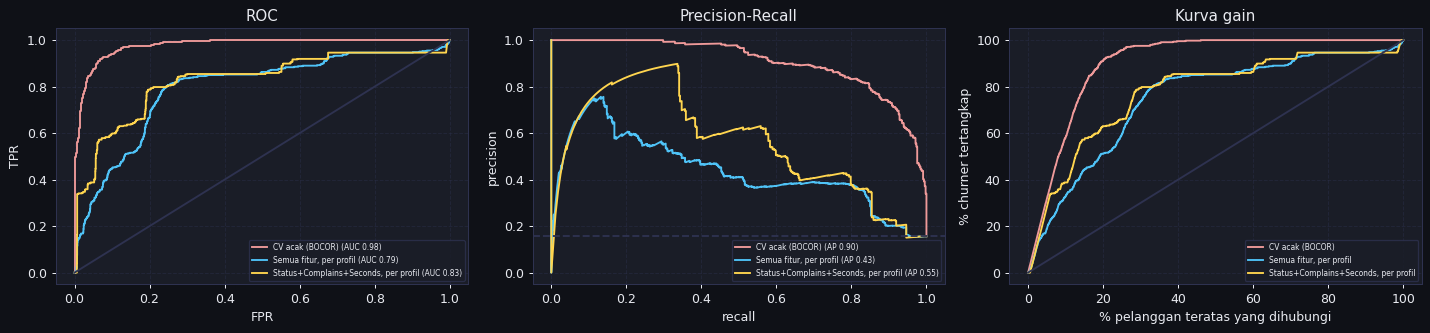

,model,top-K %,n dihubungi,precision %,recall %,lift
0,Status+Complains+Seconds,5,142,88.0,28.0,5.6
1,Semua fitur,5,142,59.2,18.8,3.8
2,Status+Complains+Seconds,10,285,60.7,38.8,3.9
3,Semua fitur,10,285,51.6,33.0,3.3
4,Status+Complains+Seconds,20,570,49.3,63.0,3.2
5,Semua fitur,20,570,40.0,51.1,2.6
6,Status+Complains+Seconds,30,855,41.4,79.4,2.6
7,Semua fitur,30,855,38.4,73.5,2.5
8,Status+Complains+Seconds,40,1140,33.4,85.4,2.1
9,Semua fitur,40,1140,32.9,84.1,2.1



- KS model sederhana = **0.59**, model semua fitur = 0.56 (CV per profil). Pada top 10% pelanggan, model sederhana menangkap **39%** churner (lift 3.9×).
- Kurva "CV acak" memperlihatkan seberapa menyesatkannya evaluasi bocor: AP 0.90 vs 0.43 untuk model yang sama dengan evaluasi jujur.
- Karena pembagiannya per profil, hasil per desil dikendalikan oleh beberapa profil saja; **jangan menjanjikan angka lift ini ke bisnis** tanpa data tambahan.


In [27]:
def decile_table(p, label):
    d = pd.DataFrame({'p': p, 'y': df[TARGET].values}); d['desil'] = pd.qcut(d.p.rank(method='first', ascending=False), 10, labels=range(1, 11))
    t = d.groupby('desil', observed=True).agg(n=('y', 'size'), churn=('y', 'sum')); t['rate %'] = t.churn / t.n * 100
    t['lift'] = t['rate %'] / BASE; t['recall kumulatif %'] = t.churn.cumsum() / t.churn.sum() * 100; t['model'] = label
    return t

p_simple, p_all, p_rand = P_store['Status + Complains + Seconds_of_Use'], P_store['Semua fitur'], P_rand.mean(0)
t_simple, t_all = decile_table(p_simple, 'Status+Complains+Seconds'), decile_table(p_all, 'Semua fitur (per profil)')
display(t_simple[['n', 'churn', 'rate %', 'lift', 'recall kumulatif %']].round(1))

def ks_stat(p):
    fpr, tpr, _ = roc_curve(df[TARGET], p); return (tpr - fpr).max()
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for p, nm, col in [(p_rand, 'CV acak (BOCOR)', C1), (p_all, 'Semua fitur, per profil', C0), (p_simple, 'Status+Complains+Seconds, per profil', ACC)]:
    fpr, tpr, _ = roc_curve(df[TARGET], p); axes[0].plot(fpr, tpr, color=col, label=f'{nm} (AUC {roc_auc_score(df[TARGET], p):.2f})')
    pr, rc, _ = precision_recall_curve(df[TARGET], p); axes[1].plot(rc, pr, color=col, label=f'{nm} (AP {average_precision_score(df[TARGET], p):.2f})')
    order = np.argsort(-p); cum = np.cumsum(df[TARGET].values[order]) / N_CHURN; axes[2].plot(np.arange(1, N + 1) / N * 100, cum * 100, color=col, label=nm)
axes[0].plot([0, 1], [0, 1], color=GRID); axes[0].set_title('ROC'); axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR'); axes[0].legend(fontsize=6)
axes[1].axhline(BASE / 100, color=GRID, ls='--'); axes[1].set_title('Precision-Recall'); axes[1].set_xlabel('recall'); axes[1].set_ylabel('precision'); axes[1].legend(fontsize=6)
axes[2].plot([0, 100], [0, 100], color=GRID); axes[2].set_title('Kurva gain'); axes[2].set_xlabel('% pelanggan teratas yang dihubungi'); axes[2].set_ylabel('% churner tertangkap'); axes[2].legend(fontsize=6)
plt.tight_layout(); plt.show()

rows = []
for k in [5, 10, 20, 30, 40]:
    for nm, p in [('Status+Complains+Seconds', p_simple), ('Semua fitur', p_all)]:
        top = np.argsort(-p)[:int(N * k / 100)]; ch = df[TARGET].values[top]
        rows.append({'model': nm, 'top-K %': k, 'n dihubungi': len(top), 'precision %': ch.mean() * 100, 'recall %': ch.sum() / N_CHURN * 100, 'lift': ch.mean() / (BASE / 100)})
topk = pd.DataFrame(rows); display(topk.round(1))
md(f"""
- KS model sederhana = **{ks_stat(p_simple):.2f}**, model semua fitur = {ks_stat(p_all):.2f} (CV per profil). Pada top 10% pelanggan, model sederhana menangkap **{topk[(topk.model == 'Status+Complains+Seconds') & (topk['top-K %'] == 10)]['recall %'].iloc[0]:.0f}%** churner (lift {topk[(topk.model == 'Status+Complains+Seconds') & (topk['top-K %'] == 10)]['lift'].iloc[0]:.1f}×).
- Kurva "CV acak" memperlihatkan seberapa menyesatkannya evaluasi bocor: AP {average_precision_score(df[TARGET], p_rand):.2f} vs {average_precision_score(df[TARGET], p_all):.2f} untuk model yang sama dengan evaluasi jujur.
- Karena pembagiannya per profil, hasil per desil dikendalikan oleh beberapa profil saja; **jangan menjanjikan angka lift ini ke bisnis** tanpa data tambahan.
""")

## C. Titik impas retensi (skenario, bukan estimasi)

In [28]:
# ASUMSI (bukan dari data): biaya kontak c, peluang berhasil s, nilai pelanggan yang dipertahankan v. Profit per orang dihubungi = precision * s * v - c.
# Titik impas precision* = c / (s * v). Tabel ini hanya menjawab: sampai top-K berapa precision model masih >= precision*.
grid_r = [0.15, 0.25, 0.35, 0.50, 0.65]
Ks = np.arange(2, 61, 2)
prec_at = lambda p, k: df[TARGET].values[np.argsort(-p)[:int(N * k / 100)]].mean()
be = pd.DataFrame({'precision* (c/(s·v))': grid_r,
                   'K maks, Status+Complains+Seconds (%)': [max([k for k in Ks if prec_at(p_simple, k) >= r], default=0) for r in grid_r],
                   'K maks, Semua fitur (%)': [max([k for k in Ks if prec_at(p_all, k) >= r], default=0) for r in grid_r]})
display(be)
md(f"""
Cara membaca: bila biaya kontak per orang sama dengan `precision*` × (peluang sukses × nilai yang diselamatkan), kampanye masih untung selama presisi model di top-K ≥ `precision*`. Misalnya pada `precision* = 0.35`, kampanye layak sampai top-{be.loc[2, 'K maks, Status+Complains+Seconds (%)']}% pelanggan menurut model sederhana. **Asumsi c, s, v harus datang dari bisnis**, bukan dari dataset ini; `Customer_Value` di sini adalah skor hasil rumus (FASE 2 B), bukan nilai uang.
""")

,precision* (c/(s·v)),"K maks, Status+Complains+Seconds (%)","K maks, Semua fitur (%)"
0,0.15,60,60
1,0.25,52,52
2,0.35,36,36
3,0.50,18,10
4,0.65,8,2



Cara membaca: bila biaya kontak per orang sama dengan `precision*` × (peluang sukses × nilai yang diselamatkan), kampanye masih untung selama presisi model di top-K ≥ `precision*`. Misalnya pada `precision* = 0.35`, kampanye layak sampai top-36% pelanggan menurut model sederhana. **Asumsi c, s, v harus datang dari bisnis**, bukan dari dataset ini; `Customer_Value` di sini adalah skor hasil rumus (FASE 2 B), bukan nilai uang.


## D. Value at Risk (deskriptif) dan matriks nilai × risiko

In [29]:
cv_total = df.Customer_Value.sum(); cv_lost = df.loc[df[TARGET] == 1, 'Customer_Value'].sum()
ns = df.groupby('seed').Customer_Value.sum().reindex(range(N_SEEDS), fill_value=0).values
ls = df[df[TARGET] == 1].groupby('seed').Customer_Value.sum().reindex(range(N_SEEDS), fill_value=0).values
bi = rng.integers(0, N_SEEDS, (3000, N_SEEDS)); share_boot = ls[bi].sum(1) / ns[bi].sum(1) * 100
ci_share = np.percentile(share_boot, [2.5, 97.5])

CS = (df.Complains == 1) | (df.Status == 2)
RULES = {'Status = 2': df.Status == 2, 'Complains = 1 OR Status = 2': CS,
         '... + Seconds kuartil terendah': CS | (pd.qcut(df[S_], 4, labels=False) == 0), '... + tenure <= 12 bulan': CS | (df.Subscription_Length <= 12)}
rows = []
for nm, m in RULES.items():
    ch = int(df.loc[m, TARGET].sum()); lo, hi = cluster_boot_ci(m)
    rows.append({'aturan': nm, 'n': int(m.sum()), '% populasi': m.mean() * 100, 'churn % (presisi)': ch / m.sum() * 100, 'CI klaster %': f'{lo:.0f}-{hi:.0f}',
                 'recall %': ch / N_CHURN * 100, '% total nilai': df.loc[m, 'Customer_Value'].sum() / cv_total * 100})
rules_df = pd.DataFrame(rows).set_index('aturan'); display(rules_df.round(1))
base_rule = rules_df.loc['Complains = 1 OR Status = 2']

risk_hi = pd.Series(p_simple, index=df.index) >= np.quantile(p_simple, 0.8)
val_hi = df.Customer_Value >= df.Customer_Value.median()
mx = pd.crosstab(val_hi.map({True: 'nilai tinggi', False: 'nilai rendah'}), risk_hi.map({True: 'risiko tinggi (top 20%)', False: 'risiko lebih rendah'}))
mx_ch = df.groupby([val_hi.map({True: 'nilai tinggi', False: 'nilai rendah'}), risk_hi.map({True: 'risiko tinggi (top 20%)', False: 'risiko lebih rendah'})])[TARGET].mean().unstack() * 100
display(mx); display(mx_ch.round(1))
md(f"""
- Seluruh Customer_Value milik churner = **{cv_lost / cv_total * 100:.1f}%** dari total nilai (CI klaster {ci_share[0]:.1f}-{ci_share[1]:.1f}%), padahal churn = {BASE:.1f}% dari baris. Churner umumnya bernilai rendah, tetapi ingat bahwa Customer_Value adalah fungsi pemakaian dan usia, jadi ini kembali ke fakta bahwa churner berpemakaian rendah.
- `Complains OR Status=2`: n = {int(base_rule['n'])}, presisi {base_rule['churn % (presisi)']:.1f}% (CI klaster {base_rule['CI klaster %']}%), recall {base_rule['recall %']:.1f}%. Menambah kriteria pemakaian rendah atau tenure ≤ 12 menaikkan recall tetapi menurunkan presisi; lihat tabel.
- Matriks nilai × risiko: segmen **nilai tinggi dan risiko tinggi** berisi {int(mx.loc['nilai tinggi', 'risiko tinggi (top 20%)'])} baris, sedangkan **nilai rendah dan risiko tinggi** {int(mx.loc['nilai rendah', 'risiko tinggi (top 20%)'])}. Hampir seluruh pelanggan berisiko adalah pelanggan bernilai rendah.
""")

,n,% populasi,churn % (presisi),CI klaster %,recall %,% total nilai
aturan,,,,,,
Status = 2,684,24.0,47.5,21-75,72.9,5.3
Complains = 1 OR Status = 2,765,26.8,49.9,25-75,85.7,7.7
... + Seconds kuartil terendah,992,34.8,40.8,20-62,90.8,11.0
... + tenure <= 12 bulan,869,30.5,46.7,23-70,91.0,12.3


col_0,risiko lebih rendah,risiko tinggi (top 20%)
Customer_Value,,
nilai rendah,912,513
nilai tinggi,1368,57


,risiko lebih rendah,risiko tinggi (top 20%)
Customer_Value,,
nilai rendah,13.8,48.5
nilai tinggi,2.9,56.1



- Seluruh Customer_Value milik churner = **4.4%** dari total nilai (CI klaster 1.7-8.7%), padahal churn = 15.6% dari baris. Churner umumnya bernilai rendah, tetapi ingat bahwa Customer_Value adalah fungsi pemakaian dan usia, jadi ini kembali ke fakta bahwa churner berpemakaian rendah.
- `Complains OR Status=2`: n = 765, presisi 49.9% (CI klaster 25-75%), recall 85.7%. Menambah kriteria pemakaian rendah atau tenure ≤ 12 menaikkan recall tetapi menurunkan presisi; lihat tabel.
- Matriks nilai × risiko: segmen **nilai tinggi dan risiko tinggi** berisi 57 baris, sedangkan **nilai rendah dan risiko tinggi** 513. Hampir seluruh pelanggan berisiko adalah pelanggan bernilai rendah.


# FASE 7: Serah-terima ke `model.ipynb`

In [30]:
ART = Path('artifacts'); ART.mkdir(exist_ok=True)
folds = pd.DataFrame(index=df.index)
for r in range(3):
    f = np.full(N, -1)
    for k, (_, te) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=SEED + r).split(df[FEATURES], df[TARGET], df.seed)):
        f[te] = k
    folds[f'fold_r{r}'] = f
clean = pd.concat([df[['orig_pos', 'seed', 'seed_churn'] + FEATURES + [TARGET]], folds], axis=1)
clean.to_csv(ART / 'Customer_Churn_clean.csv', index=False)

spec = {
    'dataset': {'rows_after_dedup': N, 'churn_rate_pct': round(BASE, 3), 'n_profiles': N_SEEDS, 'n_churn_profiles': N_CHURN_SEEDS,
                'effective_sample_size': round(float(N_EFF), 1), 'icc_churn': round(float(ICC_Y), 3)},
    'cv_protocol': {'splitter': 'StratifiedGroupKFold(n_splits=5, shuffle=True)', 'groups': f'seed (= orig_pos mod {N_SEEDS})', 'columns': list(folds.columns),
                    'forbidden': 'random row-wise split or random holdout (contaminated by sibling rows)',
                    'metrics': ['PR-AUC', 'ROC-AUC', 'recall@top-K'], 'uncertainty': 'bootstrap over profiles (seed), not rows'},
    'baseline_to_beat': {'features': ['Status', 'Complains', 'Seconds_of_Use'], 'group_cv_auc': round(float(sens.loc['Status + Complains + Seconds_of_Use', 'AUC per profil']), 3)},
    'features': {
        'robust_signal': tahan, 'weak_or_unproven': tdk + sebagian,
        'drop': {'Age': 'redundant with Age_Group (1:1)', 'Customer_Value': 'exact function of Seconds_of_Use, Frequency_of_use, Frequency_of_SMS and Age_Group'},
        'indistinguishable_in_group_cv_when_dropped': [v[2:] for v in abl.index[abl.verdict == 'tidak terbedakan'] if not v.startswith('- {')],
        'profile_level_numeric_signal': {'p_raw_lt_0.05': usage_raw, 'p_BH_lt_0.05': usage_bh},
        'leakage_risk': {'Complains': 'near-mechanical relation to label within profiles', 'Status': 'non-active accounts always have low usage and Charge_Amount = 0'},
        'profile_fingerprints_high_icc': icc_tab.drop(TARGET)[icc_tab.drop(TARGET) > 0.8].index.tolist()},
    'sensitivity_group_cv_auc': {k: round(float(v), 3) for k, v in sens['AUC per profil'].items()},
}
(ART / 'feature_spec.json').write_text(json.dumps(spec, indent=2, ensure_ascii=False, default=str), encoding='utf-8')
print('Disimpan:', [str(p) for p in sorted(ART.glob('*'))])
md(f"""
**Keluaran** (folder `artifacts/`):
- `Customer_Churn_clean.csv`: data bersih ({N:,} baris) + `orig_pos`, `seed` (kelompok CV), `seed_churn`, dan tiga penugasan fold per-profil (`fold_r0..r2`).
- `feature_spec.json`: protokol CV, baseline, keputusan fitur, dan risiko kebocoran.

**Checklist untuk `model.ipynb`:**
1. **Jangan** memakai `train_test_split` baris-acak atau CV acak. Pakai `StratifiedGroupKFold` dengan grup `seed` (atau kolom `fold_r*`).
2. Laporkan PR-AUC, ROC-AUC, dan recall@top-K dengan **CI bootstrap-profil**; sertakan baseline `Status + Complains + Seconds_of_Use`.
3. Jangan menyetel hiperparameter di CV acak; pakai nested CV per profil bila perlu. Model berkapasitas besar akan menghafal profil.
4. Evaluasi dengan dan tanpa `Status`/`Complains` (FASE 5 B) dan beri label jelas pada klaim "memprediksi sebelum sinyal muncul".
5. Jangan menghitung SMOTE/oversampling sebelum split; saudara-saudara baris akan bocor.
6. Perlakukan performa ({a_grp.mean():.2f} AUC per profil) sebagai batas atas yang **rapuh**: data hanya mewakili {N_SEEDS} profil dan kemungkinan sintetis. Validasi pada data pelanggan nyata sebelum klaim apa pun.
""")

Disimpan: ['artifacts\\Customer_Churn_clean.csv', 'artifacts\\feature_spec.json']



**Keluaran** (folder `artifacts/`):
- `Customer_Churn_clean.csv`: data bersih (2,850 baris) + `orig_pos`, `seed` (kelompok CV), `seed_churn`, dan tiga penugasan fold per-profil (`fold_r0..r2`).
- `feature_spec.json`: protokol CV, baseline, keputusan fitur, dan risiko kebocoran.

**Checklist untuk `model.ipynb`:**
1. **Jangan** memakai `train_test_split` baris-acak atau CV acak. Pakai `StratifiedGroupKFold` dengan grup `seed` (atau kolom `fold_r*`).
2. Laporkan PR-AUC, ROC-AUC, dan recall@top-K dengan **CI bootstrap-profil**; sertakan baseline `Status + Complains + Seconds_of_Use`.
3. Jangan menyetel hiperparameter di CV acak; pakai nested CV per profil bila perlu. Model berkapasitas besar akan menghafal profil.
4. Evaluasi dengan dan tanpa `Status`/`Complains` (FASE 5 B) dan beri label jelas pada klaim "memprediksi sebelum sinyal muncul".
5. Jangan menghitung SMOTE/oversampling sebelum split; saudara-saudara baris akan bocor.
6. Perlakukan performa (0.79 AUC per profil) sebagai batas atas yang **rapuh**: data hanya mewakili 50 profil dan kemungkinan sintetis. Validasi pada data pelanggan nyata sebelum klaim apa pun.


# Executive Summary

In [31]:
def cr(mask):
    s = df.loc[mask, TARGET]; return len(s), int(s.sum()), s.mean() * 100
c1, c0 = cr(df.Complains == 1), cr(df.Complains == 0); s2, s1 = cr(df.Status == 2), cr(df.Status == 1)
s2c0 = cr((df.Status == 2) & (df.Complains == 0))

md(f"""
**Konteks.** {N:,} baris unik setelah menghapus {n_extra} duplikat persis dari {n_raw:,}; churn {BASE:.1f}% ({N_CHURN} baris). Fitur dari 9 bulan pertama, label di bulan ke-12. Semua temuan **asosiatif**.

### 1. Temuan inti: data = {N_SEEDS} profil × salinan berjitter
- Urutan baris berperiode {PERIOD}: autokorelasi `Seconds_of_Use` {acf_s[PERIOD - 1]:.2f} pada lag {PERIOD} vs ~{raw[S_].autocorr(PERIOD - 1):.2f} pada lag {PERIOD - 1}; label sama pada {(raw[TARGET].values[:-PERIOD] == raw[TARGET].values[PERIOD:]).mean() * 100:.0f}% pasangan. Hasil sama pada salinan resmi UCI (identik dengan CSV ini).
- ICC label {ICC_Y:.2f}, design effect {DEFF:.0f}, **sampel efektif ≈ {N_EFF:.0f}** dengan **{N_CHURN_SEEDS} profil churn**.
- Akibat: p-value/CI tingkat baris terlalu optimistis; CV acak membocorkan (**AUC {a_rand.mean():.2f} acak vs {a_grp.mean():.2f} per profil**); sampel acak holdout tidak sah.
- Dua makalah yang memakai data ini (PLOS ONE 2024; ALMUISY 2026) melaporkan hasil tinggi dengan pembagian acak per baris. Pipeline mereka **terreplikasi** pada data ini (skema ALMUISY: ROC-AUC {alm_r['ROC-AUC']:.3f}); dengan pembagian per profil turun ke {alm_g['ROC-AUC']:.2f} (indikatif, berisik).

### 2. Yang tahan uji pada tingkat profil
{chr(10).join('- ' + t for t in tahan) if tahan else '- (tidak ada)'}
- Pemakaian (median profil, uji Mann-Whitney): {', '.join(usage_bh) if usage_bh else 'tidak ada fitur yang lolos koreksi BH'}

Tidak tahan / tidak cukup bukti: {'; '.join(tdk + sebagian) if (tdk + sebagian) else '-'}.

### 3. Hubungan paling kuat, dan kewaspadaannya
- `Complains = 1`: churn {c1[2]:.1f}% vs {c0[2]:.1f}%, **nyaris mekanis terhadap label** di dalam profil (FASE 2 D); berisiko mendekati kebocoran label.
- `Status = 2`: churn {s2[2]:.1f}% vs {s1[2]:.1f}%; Status 2 tanpa komplain {s2c0[2]:.1f}% (n = {s2c0[0]}). Pemakaian Status 2 tidak pernah melewati {df.loc[df.Status == 2, S_].max():,.0f} detik (Status 1 hingga {df.loc[df.Status == 1, S_].max():,.0f}) dan Charge_Amount-nya selalu 0; Status 2 kemungkinan *akibat* dari akun yang sedang berhenti.
- Pemakaian: median profil churn lebih rendah (Seconds {seed_cmp.loc['Seconds_of_Use', 'median profil churn']:,.0f} vs {seed_cmp.loc['Seconds_of_Use', 'median profil non-churn']:,.0f}), tetapi lolos koreksi BH pada tingkat profil untuk: {', '.join(usage_bh) if usage_bh else 'tidak ada fitur'}. Model hanya-pemakaian per profil: AUC {sens.loc['Hanya pemakaian (4 fitur)', 'AUC per profil']:.2f}.

### 4. Sifat data
- `Customer_Value` = m(Age_Group) × (0.04·detik + 0.04·panggilan + 4·SMS): fungsi pasti, tanpa informasi independen.
- Digit terakhir `Seconds_of_Use` hanya {sorted(set(range(10)) - set(absent_digits))}: tidak alami. {int(viol.sum())} baris dengan nomor berbeda > Frequency_of_use (bukan pelanggaran bila itu panggilan masuk, definisi PLOS). Dokumentasi menyebut kolom ID yang tidak ada di CSV, dan Charge Amount 0-10 (dokumentasi 0-9).
- Duplikat persis hanyalah kasus ekstrem dari replikasi; Charge_Amount = 0 selalu memuat seluruh Status 2.

### 5. Implikasi pemodelan
- Baseline per profil: `Status + Complains + Seconds_of_Use` AUC **{sens.loc['Status + Complains + Seconds_of_Use', 'AUC per profil']:.2f}**; semua fitur {sens.loc['Semua fitur', 'AUC per profil']:.2f}; tanpa Status & Complains {sens.loc['Semua tanpa Status & Complains', 'AUC per profil']:.2f}. Menambah fitur tidak membantu.
- Rekayasa fitur rasio tidak memberi bukti tambahan per profil; fitur ber-ICC tinggi (tenure, usia, call failure) adalah sidik jari profil dan tidak boleh dipakai sebagai "alasan" tanpa validasi per profil.
- Bisnis: churner = {BASE:.1f}% baris tetapi {cv_lost / cv_total * 100:.1f}% nilai (skor). Simulasi anggaran perlu asumsi biaya dari pihak bisnis.

### Keterbatasan
- Dengan ~{N_SEEDS} profil dan {N_CHURN_SEEDS} profil positif, **tidak ada kesimpulan tentang perilaku pelanggan yang dapat dipercaya kuat**; yang diperoleh adalah gambaran struktur dataset.
- Mekanisme pembuatan data tidak diketahui; "sintetis/augmentasi" adalah dugaan paling konsisten, belum terkonfirmasi (makalah asli tidak dapat diakses).
- Diagnostik berbasis model adalah alat bantu, bukan evaluasi final. Semua keputusan fitur wajib diuji ulang di notebook model dengan CV per profil.
""")


**Konteks.** 2,850 baris unik setelah menghapus 300 duplikat persis dari 3,150; churn 15.6% (446 baris). Fitur dari 9 bulan pertama, label di bulan ke-12. Semua temuan **asosiatif**.

### 1. Temuan inti: data = 50 profil × salinan berjitter
- Urutan baris berperiode 50: autokorelasi `Seconds_of_Use` 0.99 pada lag 50 vs ~0.12 pada lag 49; label sama pada 98% pasangan. Hasil sama pada salinan resmi UCI (identik dengan CSV ini).
- ICC label 0.92, design effect 53, **sampel efektif ≈ 54** dengan **8 profil churn**.
- Akibat: p-value/CI tingkat baris terlalu optimistis; CV acak membocorkan (**AUC 0.98 acak vs 0.79 per profil**); sampel acak holdout tidak sah.
- Dua makalah yang memakai data ini (PLOS ONE 2024; ALMUISY 2026) melaporkan hasil tinggi dengan pembagian acak per baris. Pipeline mereka **terreplikasi** pada data ini (skema ALMUISY: ROC-AUC 0.993); dengan pembagian per profil turun ke 0.74 (indikatif, berisik).

### 2. Yang tahan uji pada tingkat profil
- Complains = 1
- Status = 2 (non-aktif)
- Pemakaian (median profil, uji Mann-Whitney): tidak ada fitur yang lolos koreksi BH

Tidak tahan / tidak cukup bukti: Tenure <= 12 bulan; Seconds_of_Use kuartil terendah; Distinct_Called_Numbers kuartil terendah; Call_Failure kuartil tertinggi; Tariff_Plan = 2 (contractual); Usia 15 atau 55 (Age_Group 1/5); Seconds_of_Use kuartil tertinggi; Charge_Amount = 0.

### 3. Hubungan paling kuat, dan kewaspadaannya
- `Complains = 1`: churn 82.6% vs 9.8%, **nyaris mekanis terhadap label** di dalam profil (FASE 2 D); berisiko mendekati kebocoran label.
- `Status = 2`: churn 47.5% vs 5.6%; Status 2 tanpa komplain 35.9% (n = 535). Pemakaian Status 2 tidak pernah melewati 4,005 detik (Status 1 hingga 17,090) dan Charge_Amount-nya selalu 0; Status 2 kemungkinan *akibat* dari akun yang sedang berhenti.
- Pemakaian: median profil churn lebih rendah (Seconds 1,221 vs 3,472), tetapi lolos koreksi BH pada tingkat profil untuk: tidak ada fitur. Model hanya-pemakaian per profil: AUC 0.65.

### 4. Sifat data
- `Customer_Value` = m(Age_Group) × (0.04·detik + 0.04·panggilan + 4·SMS): fungsi pasti, tanpa informasi independen.
- Digit terakhir `Seconds_of_Use` hanya [0, 2, 3, 5, 7, 8]: tidak alami. 111 baris dengan nomor berbeda > Frequency_of_use (bukan pelanggaran bila itu panggilan masuk, definisi PLOS). Dokumentasi menyebut kolom ID yang tidak ada di CSV, dan Charge Amount 0-10 (dokumentasi 0-9).
- Duplikat persis hanyalah kasus ekstrem dari replikasi; Charge_Amount = 0 selalu memuat seluruh Status 2.

### 5. Implikasi pemodelan
- Baseline per profil: `Status + Complains + Seconds_of_Use` AUC **0.83**; semua fitur 0.79; tanpa Status & Complains 0.63. Menambah fitur tidak membantu.
- Rekayasa fitur rasio tidak memberi bukti tambahan per profil; fitur ber-ICC tinggi (tenure, usia, call failure) adalah sidik jari profil dan tidak boleh dipakai sebagai "alasan" tanpa validasi per profil.
- Bisnis: churner = 15.6% baris tetapi 4.4% nilai (skor). Simulasi anggaran perlu asumsi biaya dari pihak bisnis.

### Keterbatasan
- Dengan ~50 profil dan 8 profil positif, **tidak ada kesimpulan tentang perilaku pelanggan yang dapat dipercaya kuat**; yang diperoleh adalah gambaran struktur dataset.
- Mekanisme pembuatan data tidak diketahui; "sintetis/augmentasi" adalah dugaan paling konsisten, belum terkonfirmasi (makalah asli tidak dapat diakses).
- Diagnostik berbasis model adalah alat bantu, bukan evaluasi final. Semua keputusan fitur wajib diuji ulang di notebook model dengan CV per profil.


## Lampiran: status klaim dari versi sebelumnya

| Klaim (EDA awal / Real_EDA v1) | Status di v2 | Alasan |
|---|---|---|
| Duplikat = 300 baris, "tidak bisa dibedakan" kebetulan atau artefak | **Direvisi** | duplikat persis hanya kasus ekstrem dari replikasi 50 profil (FASE 2) |
| `Customer_Value` ≈ turunan SMS (R² 0.957) | **Direvisi** | rumus pasti dengan pengali Age_Group (R² = 1) |
| Complains dan Status sinyal terkuat | **Dipertahankan, dengan peringatan** | tahan uji klaster, tetapi Complains nyaris mekanis terhadap label |
| Pemakaian rendah → churn | **Melemah** | arah konsisten, tetapi bukti tingkat profil terbatas (FASE 4 B); model hanya-pemakaian per profil jauh di bawah Status+Complains |
| Charge_Amount = efek Status | **Dipertahankan** | fakta struktural (semua Status 2 ber-Charge 0) |
| Plan 2 lebih loyal | **Tidak tahan** | berasal dari beberapa profil; tercampur Status |
| Age_Group pola U-terbalik, "tidak boleh di-drop" | **DITARIK** | Fisher baris p = 7e-18 hanya karena pseudo-replikasi; tingkat profil tidak signifikan |
| Ambang tenure ≤ 12 bulan | **DITARIK** | berasal dari beberapa profil; tidak tahan uji klaster |
| Subscription_Length "harus dipertahankan" (uji drop CV acak) | **DITARIK** | pada CV per profil tidak penting; sidik jari profil |
| Call_Failure suppressor (p = 4e-7) | **DITARIK** | p klaster tidak signifikan |
| "AUC 0.93-0.98 adalah red flag leakage" | **Dijelaskan** | kebocoran karena salinan profil di CV acak (FASE 2 E) |
| Pencarian kombinasi 2 fitur (train/test baris) | **Dibuang** | split baris-acak tidak sah; sel-selnya berasal dari beberapa profil |
| Value at Risk: union 4 sinyal | **Disederhanakan** | hanya aturan sederhana dengan CI klaster |
| Rekomendasi drop Customer_Value dan SMS dst. | **Dipertahankan** | rumus pasti dan ablasi per profil |
| Draf sebelumnya: "AUC 93.8-94.9% PLOS sebanding dengan ROC-AUC kita" | **Dikoreksi** | metrik PLOS = akurasi seimbang (1+TPR-FPR)/2, bukan ROC-AUC; pipeline mereka direplikasi di FASE 2 E |
| Draf sebelumnya: 111 baris Distinct > Frequency adalah anomali | **Dilunakkan** | bukan pelanggaran bila Frequency_of_use = panggilan masuk (definisi PLOS) |

Catatan: dokumen `kelemahan/Review_Kelemahan_EDA.docx` ditulis berdasarkan analisis tingkat baris sehingga sebagian butirnya (Age_Group, tenure, Call_Failure) perlu dibaca bersama tabel ini.